[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QClassifier_AdversarialGeneralization_Georgiou2024.ipynb)

# Adversarial generalisation of a single-qubit quantum classifier: Georgiou, Jose and Simeone (2024) step by step

**Paper.** Petros Georgiou, Sharu Theresa Jose and Osvaldo Simeone, *Adversarial Quantum Machine Learning: An Information-Theoretic Generalization Analysis*, 2024 IEEE International Symposium on Information Theory (ISIT), arXiv:2402.00176 [quant-ph]. DOI [10.1109/ISIT57864.2024.10619403](https://doi.org/10.1109/isit57864.2024.10619403). University of Birmingham and King's College London.

**What this notebook does.** A quantum classifier can be fooled by an *attacker* who nudges the quantum state that encodes the input. The defence studied in the paper is *adversarial training*: the classifier is trained on the worst-case nudged states. The paper proves upper bounds on how much worse such a classifier does on new data than on its training data (its *generalisation error*). Only the last section of the paper (Section VI, Fig. 2) contains numbers; Theorems 1 to 5 and the appendices are mathematics. This notebook re-runs exactly that numerical study:

1. generates the paper's own synthetic data (two Gaussian classes, finely quantised) and encodes every input into one noisy qubit, `rho(x) = (1 - q) |x><x| + q I/2`;
2. builds the embedding circuit in PennyLane (`default.mixed`) and **asserts that the NumPy density matrices used for all computations equal the simulator's**;
3. implements the `p = 1` Schatten attack with the closed form of Appendix A, eq. (28), and two physically stricter versions of it;
4. measures the true generalisation errors `G` and `G_{1,eps}` as a function of the training-set size `T` by Monte Carlo, together with the Rademacher-based uniform-deviation bounds (13) and (17) at `delta = 0.8`;
5. evaluates the paper's bounds (10), (18) and (20) and re-draws Fig. 2;
6. checks Assumption 1 and documents an inconsistency in the paper's constants (`Delta = 0.05` versus the `q/2 = 0.025` that the stated embedding really has);
7. adds a classical baseline on the same quantised scalar inputs, with clean and adversarial error at the same budget `eps`;
8. prints the paper's claims next to the measured outcomes with one verdict each.

**How to run.** Colab, CPU runtime, *Runtime -> Run all*. `FAST_MODE = True` is a class demo (about 2 to 4 minutes, most of it start-up); `FAST_MODE = False` uses the larger Monte Carlo budgets listed in the configuration cell (about 4 to 6 minutes on a laptop CPU). Everything is simulated exactly on a CPU (the paper does the same for a single qubit). No download, no token and no quantum hardware are needed.

**What you get at the end.** Data and circuit figures, the re-drawn Fig. 2, a supplementary figure that compares three readings of the attack, a classical-baseline table, and a verdict table for each qualitative claim of Section VI, followed by a critical reading and exercises.

## The paper in one page

**Problem.** A classical input `x` is mapped to a density matrix `rho(x)` (the *quantum embedding*) and classified by a POVM `Pi = {Pi_c}`. The loss is the probability of error `l(Pi, rho(x), c) = 1 - Tr(Pi_c rho(x))`. An adversary with white-box knowledge replaces `rho(x)` by any state `lambda` within Schatten-`p` distance `eps`; the adversarial loss `l_{p,eps}` is the worst case over such `lambda`. The *generalisation error* is the gap between population risk and training risk, `G(Pi, T) = L(Pi) - L_hat(Pi, T)`, and its adversarial version `G_{p,eps}` uses the adversarial losses.

**Decision / method.** The authors bound `G_{p,eps}` with the Rademacher-complexity route of the non-adversarial analysis of Banchi et al. (their Theorem 1 / bound (10), which contains the exponentiated 2-Renyi mutual information `I_2(X:Q)` between data and embedding). The adversarial Rademacher complexity is split into the ordinary one plus a *perturbation* term. Under Assumption 1 (every `rho(x)` has minimum eigenvalue at least `Delta`) and equiprobable classes:
* Theorem 2 (`p = 1`, `eps <= 2 Delta`): `G_{1,eps} <= B + 2 sqrt(K/T) eps`, bound (18), with `B = 2 sqrt(2^{I_2} K / T) + sqrt(2 log(2/delta)/T)` from (10);
* Theorem 3 (`p = infinity`, `eps <= Delta`): `G_{inf,eps} <= B + 2 d sqrt(K/T) eps`, bound (19);
* Theorem 4 (no assumption, any `eps`): `G_{1,eps} <= B + eps sqrt(2 d (1 + (K-1)/T))`, bound (20), which does **not** vanish with `T`;
* Theorem 5 and Lemma 2: what happens when training and test attacks differ (pure theory, not simulated).

**Data (Section VI).** Equiprobable binary class `c`, scalar feature `x_tilde ~ N(mu_c, 1)` with `mu_c = (-1)^c`, quantised finely to a discrete grid so that the sum in (11) can be evaluated by numerical integration. The grid is not specified.

**Model.** One qubit, `rho(x) = (1 - q)|x><x| + q I/2`, `|x> = U_theta(x)|0>`, `U_theta(x) = RX(x) Rot_theta RX(x)`, `Rot_theta = exp(-i theta . sigma)`, `RX(x) = exp(-i x sigma_x)`, `theta = (pi/4, pi/4, pi/4)`, `q = 0.05`, stated to give `Delta = 0.05`. Fixed POVM `Pi = {|0><0|, |1><1|}`, nothing is trained in the figure.

**Experiment and claims.** Fig. 2 plots, against the training-set size `T`, the true generalisation errors `G` and `G_{1,eps}`, the numerically evaluated Rademacher-based uniform-deviation bounds (13) and (17) at `delta = 0.8`, and the derived bounds (10), (18) (left panel, `eps = 0.08 <= 2 Delta = 0.1`) and (20) (right panel, `eps = 0.12 > 2 Delta`). The numbers on the curves are not given in the text; the *claims* are qualitative:
1. the adversarial generalisation error is larger than the non-adversarial one;
2. both errors tend to 0 as `T` grows;
3. for `eps <= 2 Delta` the derived bound (18) reproduces this behaviour;
4. the adversarial Rademacher complexity exceeds the non-adversarial one;
5. for `eps > 2 Delta` the bound (20) captures the decrease with `T` but is loose.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Classes, feature | equiprobable `c in {0,1}`, `x_tilde ~ N((-1)^c, 1)` | identical (class 0 has mean +1, class 1 mean -1) |
| Quantisation grid | "finely quantized", grid not given | CHOICE: grid step `GRID_H = 0.01` on `[-7, 7]` (1401 points), probability mass of each cell by the Gaussian CDF, renormalised; the code checks that the mass lost outside `[-7, 7]` is below 1e-8 |
| Embedding | `rho = (1-q)|x><x| + q I/d`, `U_theta(x) = RX(x) Rot_theta RX(x)`, `Rot_theta = exp(-i theta.sigma)`, `RX(x) = exp(-i x sigma_x)` | identical, taken literally (no factor 1/2 in the exponents; in PennyLane `RX(x)_paper = qml.RX(2x)`). The depolarising channel of PennyLane with probability `p = 3q/4` is exactly `q I/2` mixing; this is asserted |
| `theta`, `q` | `(pi/4)^3`, `0.05` | identical |
| `Delta` | "`q = 0.05` results in `Delta = 0.05`" | **inconsistent**: the minimum eigenvalue of `rho(x)` is `q/2 = 0.025`. Both readings are carried through (`Delta = 0.05` as printed, `Delta = 0.025` as computed) |
| POVM | `{|0><0|, |1><1|}` | identical for the "fixed POVM" curves; see the next row for the trained classifier |
| "True generalisation error" | `G(Pi,T)` and `G_{1,eps}(Pi,T)` for that POVM; how a random quantity is turned into one curve (expectation, quantile, ...) is not stated | CHOICE, all reported: (a) `E_T |G|` for the fixed POVM, (b) `E_T[G]` of the **empirically trained POVM** (adversarially trained for `G_{1,eps}`; ERM over 400 projective measurement directions plus the two trivial POVMs, which is exact for a linear loss), (c) the exact uniform deviation `E_T sup_Pi |L - L_hat|` over the same family |
| Inner maximisation, `p = 1` | eq. (28) of Appendix A: loss increases by `(eps/2)(alpha_max(Pi_c) - alpha_min(Pi_c))` | `lit`: eq. (28) exactly as printed. CHOICE (sensitivity): `clip` (same, loss capped at 1) and `exact` (true maximum over physical states, solved in closed form on the Bloch ball and checked by brute force) |
| Rademacher complexity | "evaluated numerically" | Monte Carlo over training sets and Rademacher signs; the supremum over all POVMs is taken over the same candidate family; for eq. (28) it is also computed in closed form and compared |
| Confidence `delta` | 0.8 | 0.8 (note: the high-probability statements then hold with probability `1 - delta = 0.2`) |
| Training-set sizes `T` | x-axis of Fig. 2, values not given | CHOICE: `T` from 10 to 5000 (log spaced), fewer points in `FAST_MODE` |
| Monte Carlo size | not given | `N_MC` training sets per `T` (100 fast, 1000 full), standard errors reported |
| Classical baseline | none | Bayes-optimal threshold and logistic regression on the same quantised scalar `x`, same budget `eps` (state-space `l1` attack on the output probability vector, and the usual input-space attack `|dx| <= eps`) |

## 0. Setup

The first cell installs PennyLane when it is missing (Colab ships numpy, scipy, pandas, scikit-learn and matplotlib); a prepared local environment is left untouched. The second cell holds every constant, the third imports, fixes the seeds and prints library versions.

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, scipy, pandas, scikit-learn and matplotlib.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already present; skipping pip install.")

PennyLane already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False            # True: a few minutes; False: the larger Monte Carlo budgets below
SEED = 42

# --- the paper's numbers (Section VI) ---
Q_NOISE   = 0.05            # depolarising strength q
THETA     = (3.141592653589793 / 4,) * 3       # theta = (pi/4, pi/4, pi/4)
EPS_LIST  = (0.08, 0.12)    # attack budgets of the left and right panel of Fig. 2
DELTA     = 0.8             # confidence parameter of the uniform-deviation bounds
K_CLASSES = 2               # number of classes K
D_DIM     = 2               # Hilbert-space dimension d (one qubit)
DELTA_PAPER = 0.05          # the "Delta" printed in the paper (Assumption 1)

# --- choices the paper leaves open (CHOICE) ---
GRID_MAX  = 7.0             # CHOICE: quantisation grid covers [-GRID_MAX, GRID_MAX]
GRID_H    = 0.01            # CHOICE: grid step
N_VIS     = 3000            # samples drawn for the data-exploration section
TEST_SIZE = 0.3             # split used only in the exploration section and the baseline
T_BASELINE = 1000           # training-set size for the classical baseline and the trained POVM

if FAST_MODE:
    T_LIST = [10, 30, 100, 300, 1000]
    N_MC, N_DIR, N_SEEDS_BASE = 100, 120, 5
else:
    T_LIST = [10, 20, 50, 100, 200, 500, 1000, 2000, 5000]
    N_MC, N_DIR, N_SEEDS_BASE = 1000, 400, 20
CHUNK = 100                 # training sets simulated at once (memory)
BLAS_THREADS = 2            # limit linear-algebra threads (many busy threads on a shared CPU slow the matrix products a lot)
print(f"FAST_MODE={FAST_MODE}  T_LIST={T_LIST}  N_MC={N_MC}  N_DIR={N_DIR}  seeds for baseline={N_SEEDS_BASE}")

FAST_MODE=False  T_LIST=[10, 20, 50, 100, 200, 500, 1000, 2000, 5000]  N_MC=1000  N_DIR=400  seeds for baseline=20


In [3]:
import os, sys, time, math, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, scipy, sklearn
import matplotlib
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.special import ndtr
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import pennylane as qml
from threadpoolctl import threadpool_limits
threadpool_limits(limits=BLAS_THREADS)

T0 = time.time()
np.random.seed(SEED)
rng_vis  = np.random.default_rng(SEED)        # data-exploration sample
rng_mc   = np.random.default_rng(SEED + 1)    # Monte Carlo of the generalisation errors
rng_base = np.random.default_rng(SEED + 2)    # baseline seeds
rng_test = np.random.default_rng(SEED + 3)    # unit tests
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| matplotlib", matplotlib.__version__,
      "| pennylane", qml.__version__)

python 3.12.10 | numpy 2.5.4 | scipy 1.18.1 | pandas 3.0.6 | sklearn 1.9.1 | matplotlib 3.11.2 | pennylane 0.45.1


## 1. The generator, the quantisation grid and the embedding

**Data.** The class is a fair coin, `c in {0, 1}`; given `c` the real feature is `x_tilde ~ N(mu_c, 1)` with `mu_c = (-1)^c`, so class 0 is centred at +1 and class 1 at -1 (the classes overlap, the Bayes error is `Phi(-1) = 15.9 %`). The paper quantises `x_tilde` finely so that the input is discrete and every sum over inputs, in particular the one in (11), is exact. We use a grid of 1401 equally spaced points and give each point the Gaussian probability mass of its cell. Because the input is discrete with a known distribution, **population quantities (`L(Pi)`, `I_2`, ...) can be computed exactly**, and only the training sets are random.

**Embedding.** `|x> = RX(x) Rot_theta RX(x) |0>` with the paper's conventions (`RX(x) = exp(-i x sigma_x)`, `Rot_theta = exp(-i theta . sigma)`, no factor 1/2), then the state is mixed with the maximally mixed state with weight `q`. A single-qubit density matrix is `rho = (I + s . sigma)/2` with a Bloch vector `s`; here `|s| = 1 - q = 0.95`. All risks below are exact functions of `s`, which is what the code stores.

In [4]:
# ---- Pauli matrices and the paper's gates (taken literally) ----
I2 = np.eye(2, dtype=complex)
PX = np.array([[0, 1], [1, 0]], dtype=complex)
PY = np.array([[0, -1j], [1j, 0]], dtype=complex)
PZ = np.array([[1, 0], [0, -1]], dtype=complex)
SIGMA = np.stack([PX, PY, PZ])                      # (3,2,2)

ROT = expm(-1j * (THETA[0] * PX + THETA[1] * PY + THETA[2] * PZ))      # Rot_theta = exp(-i theta . sigma)

def pure_states(x):
    """|x> = RX(x) Rot_theta RX(x) |0> for an array of inputs; RX(x) = exp(-i x sigma_x) = cos x I - i sin x sigma_x."""
    x = np.atleast_1d(np.asarray(x, dtype=float))
    rx = np.cos(x)[:, None, None] * I2 - 1j * np.sin(x)[:, None, None] * PX
    return (rx @ ROT @ rx)[:, :, 0]                 # first column = application to |0>, shape (n,2)

def bloch_of_pure(psi):
    return np.real(np.einsum("ni,aij,nj->na", psi.conj(), SIGMA, psi))

def bloch_vectors(x):
    """Bloch vector s of rho(x) = (1-q)|x><x| + q I/2, shape (n,3)."""
    return (1.0 - Q_NOISE) * bloch_of_pure(pure_states(x))

def rho_from_bloch(s):
    return 0.5 * (I2 + np.einsum("na,aij->nij", s, SIGMA))

# ---- the quantisation grid (CHOICE: step 0.01 on [-7, 7]) ----
XS = np.round(np.arange(-GRID_MAX, GRID_MAX + GRID_H / 2, GRID_H), 10)
G = len(XS)
MU = {0: +1.0, 1: -1.0}                              # mu_c = (-1)^c
PX_C = np.zeros((2, G))
for c in (0, 1):
    PX_C[c] = ndtr(XS + GRID_H / 2 - MU[c]) - ndtr(XS - GRID_H / 2 - MU[c])
mass_lost = 1 - PX_C.sum(axis=1)
assert mass_lost.max() < 1e-8, mass_lost
PX_C /= PX_C.sum(axis=1, keepdims=True)             # P(x | c) on the grid
JOINT = np.concatenate([0.5 * PX_C[0], 0.5 * PX_C[1]])   # P(x,c) flattened: cell j = c*G + k
PRIOR = np.array([0.5, 0.5])
PX_MARG = 0.5 * (PX_C[0] + PX_C[1])

S_GRID = bloch_vectors(XS)                           # (G,3)
RHO_GRID = rho_from_bloch(S_GRID)
PSI_GRID = pure_states(XS)
RHO_CHECK = (1 - Q_NOISE) * np.einsum("ni,nj->nij", PSI_GRID, PSI_GRID.conj()) + Q_NOISE * I2 / 2
assert np.allclose(RHO_GRID, RHO_CHECK, atol=1e-12), "Bloch-vector form differs from (1-q)|x><x| + q I/2"
assert np.allclose(np.trace(RHO_GRID, axis1=1, axis2=2), 1.0)

eig = np.linalg.eigvalsh(RHO_GRID)
ALPHA_MIN = eig[:, 0].min()
print(f"grid: {G} points on [{XS[0]:.2f}, {XS[-1]:.2f}], step {GRID_H}; mass outside the grid <= {mass_lost.max():.1e}")
print(f"|Bloch vector| of every rho(x): min {np.linalg.norm(S_GRID, axis=1).min():.4f}, max {np.linalg.norm(S_GRID, axis=1).max():.4f}")
print(f"smallest eigenvalue of rho(x) over the grid: {ALPHA_MIN:.5f}  (= q/2 = {Q_NOISE/2:.5f})   |  paper states Delta = {DELTA_PAPER}")
assert abs(ALPHA_MIN - Q_NOISE / 2) < 1e-12

grid: 1401 points on [-7.00, 7.00], step 0.01; mass outside the grid <= 9.6e-10
|Bloch vector| of every rho(x): min 0.9500, max 0.9500
smallest eigenvalue of rho(x) over the grid: 0.02500  (= q/2 = 0.02500)   |  paper states Delta = 0.05


## Dataset Exploration and Visualisation

**What the data are.** This paper has no external data set. Its only experiment (Section VI) draws labelled inputs from the paper's **own generative model**, two unit-variance Gaussians at -1 and +1, quantised to a grid. The samples below come from exactly that generator (no substitute, no invented labels); the training sets used later are fresh draws from the same distribution. Each real observation is the pair (quantised `x`, class `c`); its quantum encoding is the Bloch vector of `rho(x)` and the polar and azimuthal angles of the pure state `|x>`.

The cell prints the shape, the feature names and the label counts, plots the class distribution (bar chart and class-conditional histograms against the exact densities), and shows 2-D scatter plots in which every point is one real observation coloured by its ground-truth class: the raw PCA coordinates of the Bloch vectors (PCA fitted on the training split only), the same coordinates scaled to `[0, pi]` (min-max fitted on the training split, test points clipped), and the two Bloch angles.

dataset shape: (3000, 7) (rows = real generated observations, columns = 6 features + label)
feature names: ['x (quantised)', 'bloch_x', 'bloch_y', 'bloch_z', 'polar_angle', 'azimuth']
original label values: [0, 1]
class counts: {0: 1506, 1: 1494}
        mean    std   min   max
class                          
0      0.987  1.008 -1.92  4.45
1     -1.022  0.990 -4.06  2.09


PCA explained variance of the Bloch vectors (train): [0.7764 0.1128]


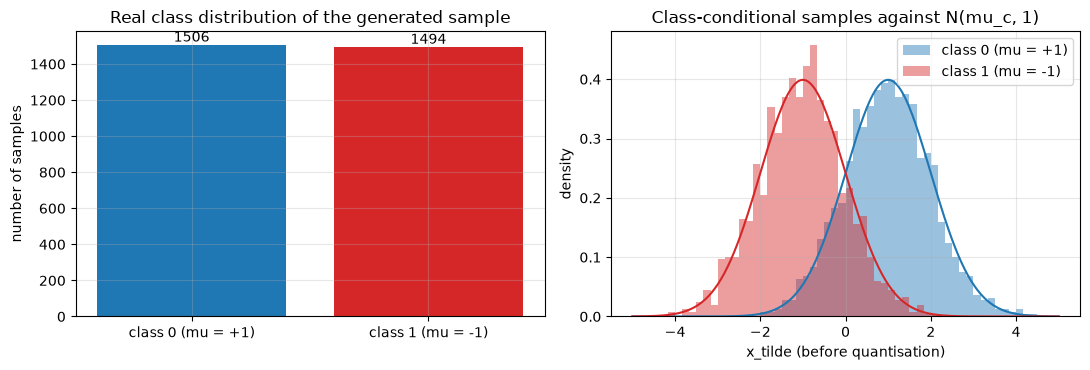

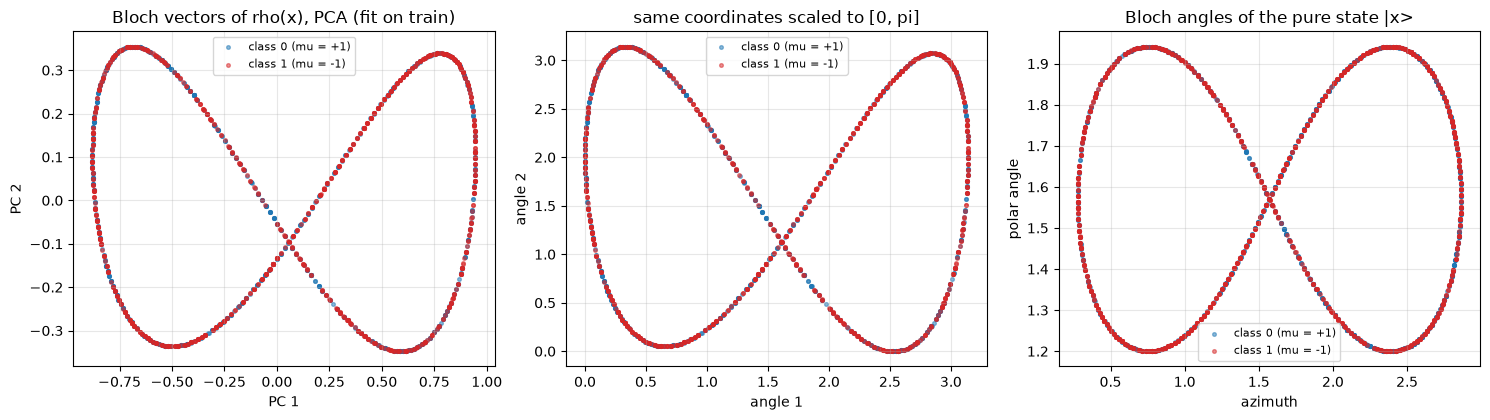

Reading the plots: the quantum encoding turns the real number x into a point on a closed 1-D curve (a figure-eight on the Bloch sphere that is traced
back and forth as x grows, because both RX gates rotate by 2x). The two classes lie on top of each other all along the curve: with these literal gate
conventions the embedding keeps very little class information (quantified in section 3, 'How informative is the embedding?').


In [5]:
# ---- draw a labelled sample from the paper's generator (continuous x_tilde, then quantise) ----
c_vis = rng_vis.integers(0, 2, size=N_VIS)                                   # equiprobable classes
xt_vis = rng_vis.normal(loc=np.where(c_vis == 0, MU[0], MU[1]), scale=1.0)   # x_tilde ~ N(mu_c, 1)
k_vis = np.clip(np.rint((xt_vis + GRID_MAX) / GRID_H).astype(int), 0, G - 1) # CHOICE: nearest grid point
x_vis = XS[k_vis]
s_vis = bloch_vectors(x_vis)
psi_vis = pure_states(x_vis)
polar = np.arccos(np.clip(bloch_of_pure(psi_vis)[:, 2], -1, 1))              # theta of |x> on the Bloch sphere
azim = np.mod(np.arctan2(bloch_of_pure(psi_vis)[:, 1], bloch_of_pure(psi_vis)[:, 0]), 2 * np.pi)
FEATURES = ["x (quantised)", "bloch_x", "bloch_y", "bloch_z", "polar_angle", "azimuth"]
DF = pd.DataFrame(np.column_stack([x_vis, s_vis, polar, azim]), columns=FEATURES)
DF["class"] = c_vis
CLASS_NAME = {0: "class 0 (mu = +1)", 1: "class 1 (mu = -1)"}
COL = {0: "#1f77b4", 1: "#d62728"}

print("dataset shape:", DF.shape, "(rows = real generated observations, columns = 6 features + label)")
print("feature names:", FEATURES)
print("original label values:", sorted(DF["class"].unique().tolist()))
print("class counts:", DF["class"].value_counts().sort_index().to_dict())
print(DF.groupby("class")["x (quantised)"].agg(["mean", "std", "min", "max"]).round(3))

idx_tr, idx_te = train_test_split(np.arange(N_VIS), test_size=TEST_SIZE, stratify=c_vis, random_state=SEED)
pca = PCA(n_components=2, random_state=SEED).fit(s_vis[idx_tr])               # fitted on the training split only
Z_tr, Z_te = pca.transform(s_vis[idx_tr]), pca.transform(s_vis[idx_te])
mm = MinMaxScaler((0, np.pi)).fit(Z_tr)
A_tr, A_te = mm.transform(Z_tr), np.clip(mm.transform(Z_te), 0, np.pi)
print(f"PCA explained variance of the Bloch vectors (train): {pca.explained_variance_ratio_.round(4)}")

# Figure 1: class distribution
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
cnt = DF["class"].value_counts().sort_index()
ax[0].bar([CLASS_NAME[i] for i in cnt.index], cnt.values, color=[COL[i] for i in cnt.index])
for i, v in enumerate(cnt.values): ax[0].text(i, v, str(v), ha="center", va="bottom")
ax[0].set_ylabel("number of samples"); ax[0].set_title("Real class distribution of the generated sample")
bins = np.linspace(-5, 5, 61); xx = np.linspace(-5, 5, 400)
for c in (0, 1):
    ax[1].hist(xt_vis[c_vis == c], bins=bins, density=True, alpha=0.45, color=COL[c], label=CLASS_NAME[c])
    ax[1].plot(xx, np.exp(-(xx - MU[c]) ** 2 / 2) / np.sqrt(2 * np.pi), color=COL[c], lw=1.5)
ax[1].set_xlabel("x_tilde (before quantisation)"); ax[1].set_ylabel("density"); ax[1].legend()
ax[1].set_title("Class-conditional samples against N(mu_c, 1)")
plt.tight_layout(); plt.show()

# Figure 2: 2-D scatter of real observations coloured by their ground-truth class
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for c in (0, 1):
    m = c_vis[idx_tr] == c
    ax[0].scatter(Z_tr[m, 0], Z_tr[m, 1], s=7, alpha=0.5, color=COL[c], label=CLASS_NAME[c])
    ax[1].scatter(A_tr[m, 0], A_tr[m, 1], s=7, alpha=0.5, color=COL[c], label=CLASS_NAME[c])
    mm_all = c_vis == c
    ax[2].scatter(azim[mm_all], polar[mm_all], s=7, alpha=0.5, color=COL[c], label=CLASS_NAME[c])
ax[0].set_title("Bloch vectors of rho(x), PCA (fit on train)"); ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2")
ax[1].set_title("same coordinates scaled to [0, pi]"); ax[1].set_xlabel("angle 1"); ax[1].set_ylabel("angle 2")
ax[2].set_title("Bloch angles of the pure state |x>"); ax[2].set_xlabel("azimuth"); ax[2].set_ylabel("polar angle")
for a in ax: a.legend(loc="best", fontsize=8)
plt.tight_layout(); plt.show()
print("Reading the plots: the quantum encoding turns the real number x into a point on a closed 1-D curve (a figure-eight on the Bloch sphere that is traced")
print("back and forth as x grows, because both RX gates rotate by 2x). The two classes lie on top of each other all along the curve: with these literal gate")
print("conventions the embedding keeps very little class information (quantified in section 3, 'How informative is the embedding?').")

## Quantum Circuit Architecture

The model of the paper has one qubit and one embedding circuit, drawn below from the **real PennyLane QNode** that the simulator (`default.mixed`) executes:

* `RX(2x)`: the paper's `RX(x) = exp(-i x sigma_x)` (PennyLane's `RX(phi)` is `exp(-i phi sigma_x / 2)`, hence the `2x`);
* `Rot(phi, theta, omega)`: the fixed unitary `Rot_theta = exp(-i theta . sigma)` with `theta = (pi/4)^3`, written as the ZYZ Euler rotation `RZ(omega) RY(theta') RZ(phi)` (equal up to an irrelevant global phase; asserted below);
* `RX(2x)` again;
* a depolarising channel. PennyLane's `DepolarizingChannel(p)` maps `rho -> (1-p) rho + (p/3)(X rho X + Y rho Y + Z rho Z) = (1 - 4p/3) rho + (4p/3) I/2`, so the paper's mixing weight `q` equals `4p/3`, i.e. `p = 3q/4 = 0.0375` (asserted);
* measurement of the computational basis, i.e. the POVM `{|0><0|, |1><1|}` (`probs`).

Nothing in the circuit is trained: the three angles of `Rot` are the fixed `theta`, and `x` is the data input. The assertions compare the QNode's density matrix and outcome probabilities with the NumPy density matrices `RHO_GRID` used for every number in this notebook. The adversary of Fig. 1(b) is not a circuit but an arbitrary quantum channel; it is handled analytically in the next sections.

Rot_theta = exp(-i theta.sigma) = Rot(phi=2.0018, theta=1.8495, omega=0.4310) up to a global phase


asserted: PennyLane default.mixed density matrices and POVM probabilities == NumPy ones at 41 grid points (atol 1e-10)
qubits: 1 | depth: 4 | gates: {'RX': 2, 'Rot': 1, 'DepolarizingChannel': 1}
parameters: 3 gate parameters in Rot (the fixed theta, NOT trained) + the data input x in two RX gates; trainable parameters: 0


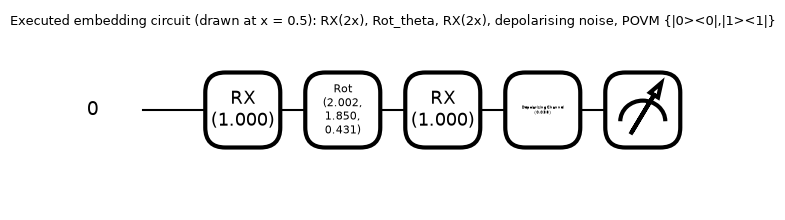

0: ──RX(1.000)──Rot(2.002,1.850,0.431)──RX(1.000)──DepolarizingChannel(0.038)─┤  Probs


In [6]:
# ---- ZYZ decomposition of Rot_theta so that the drawn circuit uses a real parametrised gate ----
def zyz_angles(U):
    """Return (phi, theta, omega) with U = e^{i g} RZ(omega) RY(theta) RZ(phi) (PennyLane's qml.Rot order)."""
    V = U / np.sqrt(np.linalg.det(U))               # SU(2) representative
    th = 2 * np.arctan2(abs(V[1, 0]), abs(V[0, 0]))
    phi = -np.angle(V[0, 0]) - np.angle(V[1, 0])
    om = -np.angle(V[0, 0]) + np.angle(V[1, 0])
    return phi, th, om

PHI_R, THT_R, OMG_R = zyz_angles(ROT)
Um = qml.matrix(qml.Rot(PHI_R, THT_R, OMG_R, wires=0))
ph = np.vdot(Um.ravel(), ROT.ravel()); ph /= abs(ph)       # global phase
assert np.allclose(Um * ph, ROT, atol=1e-10), "ZYZ decomposition of Rot_theta is wrong"
print(f"Rot_theta = exp(-i theta.sigma) = Rot(phi={PHI_R:.4f}, theta={THT_R:.4f}, omega={OMG_R:.4f}) up to a global phase")

P_DEPOL = 3 * Q_NOISE / 4                           # DepolarizingChannel(p) mixes with q = 4p/3
dev = qml.device("default.mixed", wires=1)

@qml.qnode(dev)
def embed_rho(x):
    qml.RX(2 * x, wires=0)                          # paper's RX(x) = exp(-i x sigma_x)
    qml.Rot(PHI_R, THT_R, OMG_R, wires=0)           # Rot_theta (fixed, untrained)
    qml.RX(2 * x, wires=0)
    qml.DepolarizingChannel(P_DEPOL, wires=0)       # rho -> (1-q) rho + q I/2
    return qml.density_matrix(wires=0)

@qml.qnode(dev)
def embed_povm(x):
    qml.RX(2 * x, wires=0)
    qml.Rot(PHI_R, THT_R, OMG_R, wires=0)
    qml.RX(2 * x, wires=0)
    qml.DepolarizingChannel(P_DEPOL, wires=0)
    return qml.probs(wires=0)                       # POVM {|0><0|, |1><1|}

# ---- equivalence assertions: simulator density matrix == NumPy density matrix used everywhere ----
test_idx = np.linspace(0, G - 1, 41).astype(int)
for k in test_idx:
    r_sim = np.asarray(embed_rho(float(XS[k])))
    assert np.allclose(r_sim, RHO_GRID[k], atol=1e-10), f"density matrix differs at x={XS[k]}"
    p_sim = np.asarray(embed_povm(float(XS[k])))
    p_np = np.real([RHO_GRID[k][0, 0], RHO_GRID[k][1, 1]])            # Tr(|c><c| rho)
    assert np.allclose(p_sim, p_np, atol=1e-10), f"POVM probabilities differ at x={XS[k]}"
print(f"asserted: PennyLane default.mixed density matrices and POVM probabilities == NumPy ones at {len(test_idx)} grid points (atol 1e-10)")

spec = qml.specs(embed_povm)(0.5)
n_trainable_fixed = 3
print(f"qubits: {spec.num_device_wires} | depth: {spec.resources.depth} | gates: {dict(spec.resources.gate_types)}")
print(f"parameters: {n_trainable_fixed} gate parameters in Rot (the fixed theta, NOT trained) + the data input x in two RX gates; trainable parameters: 0")
fig, ax = qml.draw_mpl(embed_povm, decimals=3)(0.5)
fig.suptitle("Executed embedding circuit (drawn at x = 0.5): RX(2x), Rot_theta, RX(2x), depolarising noise, POVM {|0><0|,|1><1|}", fontsize=9)
plt.show()
print(qml.draw(embed_povm, decimals=3)(0.5))

## 2. The attack, the loss tables and the family of POVMs

**One qubit makes everything explicit.** Write `rho = (I + s . sigma)/2` and `lambda = (I + r . sigma)/2`. Then `||rho - lambda||_1 = |r - s|` (Euclidean), so the `p = 1` attack with budget `eps` may move the Bloch vector anywhere in a ball of radius `eps` around `s`, as long as the result stays inside the Bloch ball `|r| <= 1` (this last condition is exactly "lambda is a density matrix"). If the classifier assigns class `c` the effect `Pi_c = (I + e_c . sigma)/2` (a projector), the attacker wants to minimise `Tr(Pi_c lambda) = (1 + e_c . r)/2`.

Three readings of the inner maximisation (6) are implemented; all share the same clean loss `1 - Tr(Pi_c rho)`:

* **`lit`**: eq. (28) of Appendix A exactly as printed. The attack operator is diagonal in the eigenbasis of `Pi_c`, with `+eps/2` on the eigenvalue `alpha_max` and `-eps/2` on `alpha_min`, so the loss rises by `(eps/2)(alpha_max(Pi_c) - alpha_min(Pi_c))`, a quantity that depends on the POVM only (not on `x`). The paper argues that `lambda` stays a state when `eps <= 2 Delta`.
* **`clip`**: the same, with the loss capped at 1 (a probability of error cannot exceed 1).
* **`exact`**: the true maximum over *physical* states: minimise `e_c . r` over the intersection of the ball `|r - s| <= eps` and the unit ball. This is a convex problem solved in closed form (unconstrained minimiser, or the circle where the two spheres meet, or the antipode); the cell below checks it against brute-force sampling.

**The family of POVMs.** The loss is linear in `Pi`, so for a two-outcome qubit POVM the empirical risk and the Rademacher supremum are attained at an extreme point: a rank-1 projective measurement `{(I +/- n.sigma)/2}` or one of the two trivial POVMs (always answer 0, always answer 1). We use `N_DIR` projective directions on a Fibonacci grid of the sphere (the first one is exactly `+z`, i.e. the paper's POVM) plus the two trivial POVMs. The table `LT[(variant, eps)]` stores the loss of every candidate on every (input, class) cell, so that every risk in the notebook is a matrix product.

In [7]:
def fibonacci_sphere(n):
    i = np.arange(n) + 0.5
    z = 1 - 2 * i / n
    phi = i * math.pi * (3 - math.sqrt(5))
    r = np.sqrt(1 - z ** 2)
    return np.stack([r * np.cos(phi), r * np.sin(phi), z], axis=1)

DIRS = fibonacci_sphere(N_DIR); DIRS[0] = [0.0, 0.0, 1.0]            # candidate 0 = the paper's POVM {|0><0|,|1><1|}
K_CAND = N_DIR + 2                                                   # + {Pi_0 = 0} (always answer 1) + {Pi_0 = I} (always answer 0)
SPREAD = np.concatenate([np.ones(N_DIR), np.zeros(2)])               # alpha_max(Pi_c) - alpha_min(Pi_c)

def min_dot_in_bloch(S, E, eps):
    """min of e.r over {r : |r - s| <= eps, |r| <= 1}. S:(G,3) Bloch vectors, E:(K,3) unit vectors -> (K,G)."""
    sn = np.linalg.norm(S, axis=1)[None, :]
    es = E @ S.T
    v1 = es - eps                                                     # minimiser of the ball around s ...
    feas1 = (sn ** 2 - 2 * eps * es + eps ** 2) <= 1 + 1e-12          # ... is it a physical state?
    sn_ = np.maximum(sn, 1e-12)
    a = (1 + sn ** 2 - eps ** 2) / (2 * sn_)                          # the two spheres meet on a circle at distance a along s
    rc2 = 1 - a ** 2
    cosang = np.clip(es / sn_, -1, 1)
    circ = a * cosang - np.sqrt(np.maximum(rc2, 0)) * np.sqrt(1 - cosang ** 2)
    south = (1 + 2 * es + sn ** 2) <= eps ** 2 + 1e-12                # the antipode -e of the unit ball is within eps of s
    val = np.where(feas1, v1, np.inf)
    val = np.minimum(val, np.where(rc2 >= 0, circ, np.inf))
    val = np.minimum(val, np.where(south, -1.0, np.inf))
    return val

def correct_class_prob(variant, eps):
    """Probability Tr(Pi_c lambda*) that remains on the true class after the attack: arrays (2, K, G) for c = 0, 1."""
    n_s = DIRS @ S_GRID.T                                              # n . s, (N_DIR, G)
    P0 = np.vstack([(1 + n_s) / 2, np.zeros((1, G)), np.ones((1, G))])  # Tr(Pi_0 rho)
    P = np.stack([P0, 1 - P0])
    if eps == 0:
        return P
    if variant in ("lit", "clip"):
        out = P - 0.5 * eps * SPREAD[None, :, None]                    # eq. (28): loss + (eps/2)*spread
        return np.maximum(out, 0.0) if variant == "clip" else out
    if variant == "exact":
        out = P.copy()
        m0 = min_dot_in_bloch(S_GRID, DIRS, eps)                       # class 0: e = +n
        m1 = min_dot_in_bloch(S_GRID, -DIRS, eps)                      # class 1: e = -n
        out[0, :N_DIR] = (1 + m0) / 2
        out[1, :N_DIR] = (1 + m1) / 2
        return out
    raise ValueError(variant)

def loss_table(variant, eps):
    P = correct_class_prob(variant, eps)
    return np.concatenate([1 - P[0], 1 - P[1]], axis=1)                # (K, 2G), cell j = c*G + k

VARIANTS = ("lit", "clip", "exact")
KEYS = [("clean", 0.0)] + [(v, e) for v in VARIANTS for e in EPS_LIST]
LT = {("clean", 0.0): loss_table("lit", 0.0)}
for v in VARIANTS:
    for e in EPS_LIST:
        LT[(v, e)] = loss_table(v, e)
POP = {k: LT[k] @ JOINT for k in KEYS}                                 # exact population risks of every candidate POVM
print(f"candidate POVMs: {K_CAND}; loss tables: {len(LT)} of shape {LT[('clean', 0.0)].shape}")

# ---- unit test 1: the closed-form physical attack against brute-force sampling ----
errs = []
for trial in range(40):
    s = rng_test.normal(size=3); s *= (0.95 if trial % 2 else rng_test.uniform(0.2, 0.95)) / np.linalg.norm(s)
    e = rng_test.normal(size=3); e /= np.linalg.norm(e)
    eps = [0.08, 0.12, 0.3, 1.0][trial % 4]
    u = rng_test.normal(size=(200000, 3)); u /= np.linalg.norm(u, axis=1, keepdims=True)
    u *= rng_test.uniform(size=(200000, 1)) ** (1 / 3)
    r = s + eps * u; r = r[np.linalg.norm(r, axis=1) <= 1]
    brute = (r @ e).min()
    exact = min_dot_in_bloch(s[None, :], e[None, :], eps)[0, 0]
    assert exact <= brute + 1e-9, (trial, exact, brute)              # the closed form is never beaten by a feasible point
    errs.append(brute - exact)
print(f"closed-form physical attack vs brute force (40 random cases): never beaten; mean gap {np.mean(errs):.2e}, max gap {np.max(errs):.2e} (sampling error)")

# ---- unit test 2: eq. (28) on matrices for the paper's POVM: trace distance eps, trace one, and when it stays positive ----
PI_C = [np.diag([1.0, 0.0]).astype(complex), np.diag([0.0, 1.0]).astype(complex)]
def lam_eq28(rho, c, eps):
    tau = 0.5 * eps * (PI_C[c] - (I2 - PI_C[c]))                      # +eps/2 on alpha_max(Pi_c), -eps/2 on alpha_min(Pi_c)
    return rho - tau
for eps in EPS_LIST:
    worst = 1.0
    for k in range(0, G, 37):
        for c in (0, 1):
            lam = lam_eq28(RHO_GRID[k], c, eps)
            assert abs(np.trace(lam) - 1) < 1e-12
            assert abs(np.sum(np.abs(np.linalg.eigvalsh(RHO_GRID[k] - lam))) - eps) < 1e-12      # ||rho - lambda||_1 = eps
            assert abs((1 - np.real(np.trace(PI_C[c] @ lam))) - ((1 - np.real(np.trace(PI_C[c] @ RHO_GRID[k]))) + eps / 2)) < 1e-12
            worst = min(worst, np.linalg.eigvalsh(lam)[0])
    print(f"eq. (28), eps = {eps}: trace one, ||rho - lambda||_1 = eps and loss + eps/2 verified; smallest eigenvalue of lambda over sampled inputs = {worst:+.4f}")
print(f"engine ready ({time.time() - T0:.1f} s since start)")

candidate POVMs: 402; loss tables: 7 of shape (402, 2802)


closed-form physical attack vs brute force (40 random cases): never beaten; mean gap 1.66e-03, max gap 1.31e-02 (sampling error)
eq. (28), eps = 0.08: trace one, ||rho - lambda||_1 = eps and loss + eps/2 verified; smallest eigenvalue of lambda over sampled inputs = +0.0091
eq. (28), eps = 0.12: trace one, ||rho - lambda||_1 = eps and loss + eps/2 verified; smallest eigenvalue of lambda over sampled inputs = +0.0001
engine ready (21.9 s since start)


## 3. Assumption 1 and the inconsistency in the paper's constants

Theorem 2 needs `eps <= 2 Delta`, where `Delta` is a lower bound on the smallest eigenvalue of every `rho(x)`. The paper states that `q = 0.05` "results in `Delta = 0.05`". For the stated embedding this is not so. `rho(x)` has eigenvalues `(1 +/- |s|)/2` with `|s| = 1 - q`, i.e. `1 - q/2` and `q/2`: the mixing weight `q` is spread over **two** basis states (`q I/d` with `d = 2`), so the smallest eigenvalue is `q/2 = 0.025`, not `q`. (`Delta = 0.05` would correspond to `q = 0.1`.)

We therefore carry two readings through the whole notebook: **"paper"**, `Delta = 0.05` (so `2 Delta = 0.10`: the left panel `eps = 0.08` is inside Assumption 1, the right panel `eps = 0.12` is outside), and **"computed"**, `Delta = 0.025` (`2 Delta = 0.05`: both panels are outside). The table also shows how often the attack of eq. (28) really leaves the set of density matrices (for the paper's POVM and for the worst projective POVM), which is the physical meaning of the condition `eps <= 2 Delta`.

In [8]:
DELTA_COMPUTED = ALPHA_MIN
n_s = DIRS[:N_DIR] @ S_GRID.T                                              # n . s for every projective candidate, (N_DIR, G)
SN2 = (np.linalg.norm(S_GRID, axis=1) ** 2)[None, :]
rows = []
for eps in EPS_LIST:
    # eq. (28) moves the Bloch vector to s - eps*e_c; it is a state iff |s - eps*e_c| <= 1  (e_0 = +n, e_1 = -n)
    viol0 = (SN2 - 2 * eps * n_s + eps ** 2) > 1 + 1e-12
    viol1 = (SN2 + 2 * eps * n_s + eps ** 2) > 1 + 1e-12
    mass = 0.5 * (viol0 @ PX_C[0] + viol1 @ PX_C[1])                       # P(lambda is not a density matrix), per candidate POVM
    # the same for the paper's POVM with explicit matrices on a subsample of inputs
    nbad = 0; ntot = 0; lam_min = 1.0
    for k in range(0, G, 11):
        for c in (0, 1):
            ev = np.linalg.eigvalsh(lam_eq28(RHO_GRID[k], c, eps))[0]; lam_min = min(lam_min, ev); nbad += ev < -1e-12; ntot += 1
    assert (nbad > 0) == (mass[0] > 0)
    p_loss_gt1 = 0.5 * sum(PX_C[c][(0.5 * (1 - (1 if c == 0 else -1) * S_GRID[:, 2])) + eps / 2 > 1].sum() for c in (0, 1))
    rows.append({"eps": eps,
                 "2*Delta=0.10 (paper)": "inside" if eps <= 2 * DELTA_PAPER else "OUTSIDE",
                 "2*Delta=0.05 (computed)": "inside" if eps <= 2 * DELTA_COMPUTED + 1e-12 else "OUTSIDE",
                 "paper POVM: min eig of lambda": lam_min,
                 "paper POVM: P(lambda not a state)": mass[0],
                 "P(eq.28 loss > 1), paper POVM": p_loss_gt1,
                 "worst projective POVM: P(lambda not a state)": mass.max(),
                 "share of projective POVMs with a violation": float((mass > 0).mean())})
ASSUMP = pd.DataFrame(rows)
print(f"smallest eigenvalue of rho(x) = {ALPHA_MIN:.4f} = q/2 (computed Delta); the paper prints Delta = {DELTA_PAPER}")
print(f"Assumption 1 needs Delta in (0, 1/d] = (0, {1/D_DIM}]; both values qualify, but only the computed one is true for this embedding.")
print(f"For every POVM the attack of eq. (28) is guaranteed to give a state when eps <= 1 - |s| = {1 - np.sqrt(SN2.max()):.3f} = 2*Delta_computed.")
display(ASSUMP.round(4))
print("Reading: for the paper's own POVM {|0><0|,|1><1|} and these inputs the printed attack may stay physical even above 2*Delta (see the first violation columns), because the embedded")
print("states are rarely strongly polarised against the true class along z; for other measurement directions (last two columns) eq. (28) can leave the set of density matrices, so")
print("the sufficient condition eps <= 2*Delta is not an artefact: it makes the closed form safe for *every* POVM, which is what the Rademacher supremum ranges over.")

smallest eigenvalue of rho(x) = 0.0250 = q/2 (computed Delta); the paper prints Delta = 0.05
Assumption 1 needs Delta in (0, 1/d] = (0, 0.5]; both values qualify, but only the computed one is true for this embedding.
For every POVM the attack of eq. (28) is guaranteed to give a state when eps <= 1 - |s| = 0.050 = 2*Delta_computed.


,eps,2*Delta=0.10 (paper),2*Delta=0.05 (computed),paper POVM: min eig of lambda,paper POVM: P(lambda not a state),"P(eq.28 loss > 1), paper POVM",worst projective POVM: P(lambda not a state),share of projective POVMs with a violation
0,0.08,inside,OUTSIDE,0.0091,0.0,0.0,0.3510,0.9525
1,0.12,OUTSIDE,OUTSIDE,0.0001,0.0,0.0,0.4237,0.9975


Reading: for the paper's own POVM {|0><0|,|1><1|} and these inputs the printed attack may stay physical even above 2*Delta (see the first violation columns), because the embedded
states are rarely strongly polarised against the true class along z; for other measurement directions (last two columns) eq. (28) can leave the set of density matrices, so
the sufficient condition eps <= 2*Delta is not an artefact: it makes the closed form safe for *every* POVM, which is what the Rademacher supremum ranges over.


**How informative is the embedding?** The generalisation theory is indifferent to whether the classifier is any good, but the baseline comparison below is not. The best possible POVM for equal priors has error `1/2 - (1/4) || rho_0 - rho_1 ||_1` (Helstrom), where `rho_c = sum_x P(x|c) rho(x)` is the class-averaged state. The cell computes it for the paper's gate conventions taken literally (`RX(x) = exp(-i x sigma_x)`, `Rot_theta = exp(-i theta . sigma)`) and, as a sensitivity check, for the half-angle convention (`qml.RX(x) = exp(-i x sigma_x/2)` and `exp(-i theta . sigma/2)`), which a reader implementing the circuit with library gates might use.

In [9]:
def bloch_conv(x, a):
    """Bloch vector of rho(x) when every rotation angle is multiplied by a (a = 1: paper literally, a = 1/2: library half-angle gates)."""
    x = np.atleast_1d(x)
    rot = expm(-1j * a * (THETA[0] * PX + THETA[1] * PY + THETA[2] * PZ))
    rx = np.cos(a * x)[:, None, None] * I2 - 1j * np.sin(a * x)[:, None, None] * PX
    psi = (rx @ rot @ rx)[:, :, 0]
    return (1 - Q_NOISE) * bloch_of_pure(psi)

rows = []
for a, name in ((1.0, "paper literally (angles x, theta)"), (0.5, "half-angle gates (x/2, theta/2)")):
    s_a = bloch_conv(XS, a)
    rho0, rho1 = [np.einsum("k,kij->ij", PX_C[c], rho_from_bloch(s_a)) for c in (0, 1)]
    trace_norm = np.abs(np.linalg.eigvalsh(rho0 - rho1)).sum()
    err_opt = 0.5 - 0.25 * trace_norm                                    # Helstrom error, equal priors
    err_z = 0.5 * (PX_C[0] @ ((1 - s_a[:, 2]) / 2) + PX_C[1] @ ((1 + s_a[:, 2]) / 2))   # POVM {|0><0|,|1><1|}: P(error)
    rows.append({"convention": name, "||rho_0 - rho_1||_1": trace_norm, "best possible error (Helstrom)": err_opt,
                 "error of the paper's POVM {|0><0|,|1><1|}": err_z})
HEL = pd.DataFrame(rows)
display(HEL.round(4))
assert abs(HEL.iloc[0]["error of the paper's POVM {|0><0|,|1><1|}"] - POP[("clean", 0.0)][0]) < 1e-12
print(f"classical reference: Bayes error of the scalar input = {ndtr(-1):.4f}")
print("With the literal conventions even the optimal measurement of the embedded state may be close to a coin flip (table above), so the classifier of Fig. 2 is a vehicle for the generalisation analysis rather than a good detector.")

,convention,||rho_0 - rho_1||_1,best possible error (Helstrom),"error of the paper's POVM {|0><0|,|1><1|}"
0,"paper literally (angles x, theta)",0.0939,0.4765,0.500
1,"half-angle gates (x/2, theta/2)",0.3388,0.4153,0.533


classical reference: Bayes error of the scalar input = 0.1587
With the literal conventions even the optimal measurement of the embedded state may be close to a coin flip (table above), so the classifier of Fig. 2 is a vehicle for the generalisation analysis rather than a good detector.


## 4. The paper's bounds

The non-adversarial bound (10) uses the 2-Renyi mutual information between the classical input and the quantum embedding, `I_2(X:Q) = 2 log2 Tr sqrt(sum_x P(x) rho(x)^2)` (eq. 11), evaluated exactly on the grid:

* `B(T) = 2 sqrt(2^{I_2} K / T) + sqrt(2 log(2/delta)/T)`, bound (10);
* `(18) = B + 2 sqrt(K/T) eps` (needs `eps <= 2 Delta`);
* `(20) = B + eps sqrt(2 d (1 + (K-1)/T))` for `p = 1`, any `eps` (does not vanish with `T`).

With `delta = 0.8` the statements hold with probability at least `1 - delta = 0.2` only; the paper still uses this value, and so do we.

In [10]:
M2 = np.einsum("k,kij->ij", PX_MARG, np.einsum("kij,kjl->kil", RHO_GRID, RHO_GRID))        # sum_x P(x) rho(x)^2
w_, V_ = np.linalg.eigh(M2)
SQRT_M2 = (V_ * np.sqrt(np.maximum(w_, 0))) @ V_.conj().T
I2_RENYI = 2 * np.log2(np.real(np.trace(SQRT_M2)))
print(f"I_2(X:Q) = {I2_RENYI:.4f} bits   (2^I_2 = {2 ** I2_RENYI:.4f}; maximum possible for one qubit and uniform input: log2 d = 1)")

def conf_term(T): return np.sqrt(2 * np.log(2 / DELTA) / T)
def bound_B10(T):  return 2 * np.sqrt(2 ** I2_RENYI * K_CLASSES / T) + conf_term(T)
def bound_18(T, eps): return bound_B10(T) + 2 * np.sqrt(K_CLASSES / T) * eps
def bound_20(T, eps): return bound_B10(T) + eps * np.sqrt(2 * D_DIM * (1 + (K_CLASSES - 1) / T))
BND = pd.DataFrame({"T": T_LIST})
BND["B10"] = bound_B10(BND["T"].values)
for e in EPS_LIST:
    BND[f"b18_{e}"] = bound_18(BND["T"].values, e)
    BND[f"b20_{e}"] = bound_20(BND["T"].values, e)
display(BND.round(4))

I_2(X:Q) = 0.7512 bits   (2^I_2 = 1.6832; maximum possible for one qubit and uniform input: log2 d = 1)


,T,B10,b18_0.08,b20_0.08,b18_0.12,b20_0.12
0,10,1.5885,1.6601,1.7563,1.6958,1.8402
1,20,1.1232,1.1738,1.2872,1.1991,1.3692
2,50,0.7104,0.7424,0.8720,0.7584,0.9528
3,100,0.5023,0.5250,0.6631,0.5363,0.7435
4,200,0.3552,0.3712,0.5156,0.3792,0.5958
5,500,0.2246,0.2348,0.3848,0.2398,0.4649
6,1000,0.1589,0.1660,0.3189,0.1696,0.3990
7,2000,0.1123,0.1174,0.2724,0.1199,0.3524
8,5000,0.0710,0.0742,0.2311,0.0758,0.3111


## 5. Monte Carlo: true generalisation errors and Rademacher complexities

For every training-set size `T`, `N_MC` training sets are drawn from the exact joint distribution on the grid (a multinomial over the 2 x 1401 (input, class) cells). Common random numbers are used: the same training sets and the same Rademacher signs serve every attack variant, so differences between variants are not Monte Carlo noise. For each training set and every candidate POVM the empirical risk is a matrix product with the loss table; the population risk is exact. The following quantities are recorded (mean and standard error over the `N_MC` training sets):

* **`absG_fix`**: `E_T |G(Pi, T)|` for the paper's fixed POVM (the generalisation error is random, with mean zero for a fixed `Pi`, so its typical size is measured by the mean absolute value);
* **`G_erm`**: `E_T [ L_eps(Pi_hat) - L_hat_eps(Pi_hat) ]` for the POVM `Pi_hat` that minimises the (adversarial) training risk: the generalisation error of the *trained* (adversarially trained, for `eps > 0`) classifier, the object the paper's title is about;
* **`U`**: the exact uniform deviation `E_T sup_Pi |L_eps(Pi) - L_hat_eps(Pi)|`, which bounds both of the above;
* **`R`**: the Rademacher complexity `E_T E_sigma sup_Pi (1/T) sum_n sigma_n l_eps(Pi, rho(x_n), c_n)`, whose double is the leading term of (13) and (17). For `lit` it is also evaluated by the closed-form vertex formula (`R_closed`) as a check of the candidate family.

A note on the closed form for `lit`: with eq. (28) the adversarial loss of a *given* POVM is its clean loss plus a constant `eps |v|` that does not depend on the data, so `G_{1,eps}(Pi, T) = G(Pi, T)` for every fixed `Pi` and the same holds for `U`; only the *trained* POVM and the *Rademacher* complexity change with `eps`. The cell verifies this identity numerically.

In [11]:
METRICS = ["absG_fix", "G_erm", "U", "R", "excess"]
PAIRED = ["G_erm", "R", "absG_fix"]
def run_mc():
    rows = []
    cache_closed = {}
    for T in T_LIST:
        acc = {key: {m: [] for m in METRICS + ["R_closed", "G_fix_signed"] + ["d_" + m for m in PAIRED]} for key in KEYS}
        done = 0
        while done < N_MC:
            B = min(CHUNK, N_MC - done); done += B
            counts = rng_mc.multinomial(T, JOINT / JOINT.sum(), size=B)                  # (B, 2G)
            signed = (2 * rng_mc.binomial(counts, 0.5) - counts).astype(float)          # sum of Rademacher signs per cell
            counts = counts.astype(float)
            S0 = signed[:, :G].sum(1); S1 = signed[:, G:].sum(1)
            Rv = signed[:, :G] @ S_GRID - signed[:, G:] @ S_GRID
            rr = np.arange(B)
            for key in KEYS:
                Lt, pop = LT[key], POP[key]
                emp = counts @ Lt.T / T
                gap = pop[None, :] - emp
                j = emp.argmin(1)
                a = acc[key]
                a["G_erm"].append(gap[rr, j]); a["absG_fix"].append(np.abs(gap[:, 0])); a["G_fix_signed"].append(gap[:, 0])
                a["U"].append(np.abs(gap).max(1)); a["R"].append((signed @ Lt.T / T).max(1))
                a["excess"].append(pop[j] - pop.min())
                if key == ("clean", 0.0):
                    clean_now = {"G_erm": gap[rr, j], "R": a["R"][-1], "absG_fix": a["absG_fix"][-1]}
                for m in PAIRED:
                    a["d_" + m].append(a[m][-1] - clean_now[m])                           # paired with the clean run (KEYS starts with it)
                if key[0] in ("lit",):                                                     # closed-form vertex formula for eq. (28)
                    third = 0.5 * (S0 + S1) + 0.5 * (np.linalg.norm(Rv, axis=1) + key[1] * (S0 + S1))
                    a["R_closed"].append(np.maximum.reduce([S0, S1, third]) / T)
                else:
                    a["R_closed"].append(np.full(B, np.nan))
        for key in KEYS:
            row = {"variant": key[0], "eps": key[1], "T": T}
            for m in METRICS + ["R_closed", "G_fix_signed"] + ["d_" + m for m in PAIRED]:
                v = np.concatenate(acc[key][m])
                row[m] = v.mean(); row[m + "_se"] = v.std(ddof=1) / np.sqrt(len(v))
            rows.append(row)
        print(f"  T = {T:5d} done ({time.time() - T0:.0f} s since start)")
    return pd.DataFrame(rows)

t_mc = time.time()
RES = run_mc()
print(f"Monte Carlo finished in {time.time() - t_mc:.0f} s: {N_MC} training sets per T, {len(KEYS)} (variant, eps) combinations, {K_CAND} candidate POVMs")

def curve(variant, eps, col):
    d = RES[(RES.variant == variant) & (RES.eps == eps)].set_index("T")
    return d[col]

# identity check: with eq. (28) a fixed POVM has the same generalisation error with and without the attack
for e in EPS_LIST:
    diff = np.abs(curve("lit", e, "G_fix_signed") - curve("clean", 0.0, "G_fix_signed")).max()
    print(f"eps = {e}: max_T |E[G_1,eps(Pi_fix)] - E[G(Pi_fix)]| under eq. (28) = {diff:.2e}  (identical up to float error)")
    assert diff < 1e-10
# closed-form Rademacher check
for e in EPS_LIST:
    rc, rn = curve("lit", e, "R_closed"), curve("lit", e, "R")
    rel = ((rc - rn) / rc).abs().max()
    print(f"eps = {e}: Rademacher complexity, candidate family vs closed-form vertex formula: max relative gap {rel:.3%}")
    assert rel < 0.06
RES.round(5).head(8)

  T =    10 done (31 s since start)


  T =    20 done (39 s since start)


  T =    50 done (47 s since start)


  T =   100 done (57 s since start)


  T =   200 done (73 s since start)


  T =   500 done (79 s since start)


  T =  1000 done (89 s since start)


  T =  2000 done (94 s since start)


  T =  5000 done (102 s since start)
Monte Carlo finished in 79 s: 1000 training sets per T, 7 (variant, eps) combinations, 402 candidate POVMs
eps = 0.08: max_T |E[G_1,eps(Pi_fix)] - E[G(Pi_fix)]| under eq. (28) = 1.37e-16  (identical up to float error)
eps = 0.12: max_T |E[G_1,eps(Pi_fix)] - E[G(Pi_fix)]| under eq. (28) = 1.79e-16  (identical up to float error)
eps = 0.08: Rademacher complexity, candidate family vs closed-form vertex formula: max relative gap 0.130%
eps = 0.12: Rademacher complexity, candidate family vs closed-form vertex formula: max relative gap 0.130%


,variant,eps,T,absG_fix,absG_fix_se,G_erm,G_erm_se,U,U_se,R,R_se,excess,excess_se,R_closed,R_closed_se,G_fix_signed,G_fix_signed_se,d_G_erm,d_G_erm_se,d_R,d_R_se,d_absG_fix,d_absG_fix_se
0,clean,0.00,10,0.03065,0.00072,0.16279,0.00255,0.16402,0.00252,0.15395,0.00574,0.02152,0.00041,NaN,NaN,-0.00080,0.00121,0.00000,0.00000,0.00000,0.00000,0.0,0.0
1,lit,0.08,10,0.03065,0.00072,0.15996,0.00259,0.16402,0.00252,0.15364,0.00594,0.01360,0.00066,0.15384,0.00594,-0.00080,0.00121,-0.00283,0.00032,-0.00031,0.00030,-0.0,0.0
2,lit,0.12,10,0.03065,0.00072,0.15573,0.00271,0.16402,0.00252,0.15381,0.00605,0.01609,0.00086,0.15400,0.00605,-0.00080,0.00121,-0.00706,0.00054,-0.00014,0.00045,-0.0,0.0
3,clip,0.08,10,0.03065,0.00072,0.15997,0.00259,0.16402,0.00252,0.15357,0.00594,0.01356,0.00066,NaN,NaN,-0.00080,0.00121,-0.00282,0.00032,-0.00038,0.00030,-0.0,0.0
4,clip,0.12,10,0.03065,0.00072,0.15587,0.00270,0.16406,0.00252,0.15346,0.00604,0.01603,0.00085,NaN,NaN,-0.00080,0.00121,-0.00692,0.00053,-0.00049,0.00044,-0.0,0.0
5,exact,0.08,10,0.03065,0.00072,0.15988,0.00259,0.16386,0.00252,0.15329,0.00594,0.01336,0.00065,NaN,NaN,-0.00080,0.00121,-0.00291,0.00031,-0.00066,0.00029,0.0,0.0
6,exact,0.12,10,0.03065,0.00072,0.15605,0.00268,0.16346,0.00252,0.15262,0.00602,0.01594,0.00083,NaN,NaN,-0.00080,0.00121,-0.00673,0.00049,-0.00132,0.00042,-0.0,0.0
7,clean,0.00,20,0.02213,0.00051,0.11010,0.00180,0.11196,0.00176,0.11694,0.00390,0.01963,0.00042,NaN,NaN,-0.00089,0.00087,0.00000,0.00000,0.00000,0.00000,0.0,0.0


## 6. Re-drawing Fig. 2

Left panel `eps = 0.08`, right panel `eps = 0.12`, as in the paper. Solid blue and red: true generalisation error of the standard and the adversarially trained classifier (`G_erm`; bands are +/- one standard error). Dotted blue/red: the uniform-deviation bounds (13) and (17), evaluated numerically from the Monte Carlo Rademacher complexities. Grey: bound (10). Green: bound (18). Purple: bound (20). Thin dashed black: the fixed-POVM `E|G|`. Both axes are logarithmic, so a `1/sqrt(T)` law is a straight line of slope -1/2. (The dotted curves for (13) and (17) are so close that the red one hides the blue one.) The paper draws (18) on the left and (20) on the right; here both appear on both panels so that their validity can be read off.

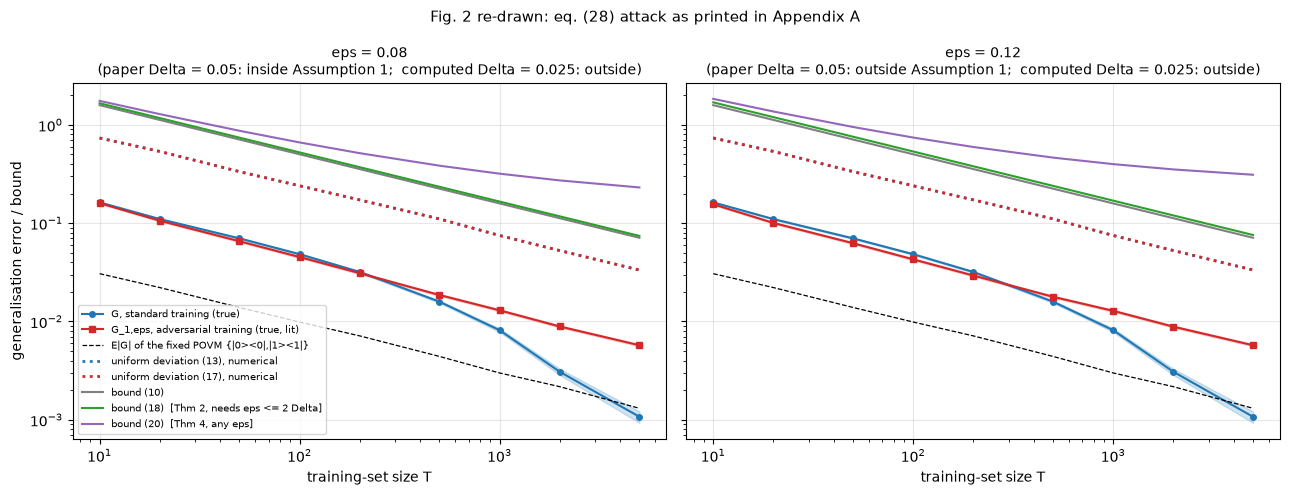

In [12]:
def fig2(variant, title, with_fixed=True):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    Ts = np.array(T_LIST)
    for ax, eps in zip(axes, EPS_LIST):
        g0, g1 = curve("clean", 0.0, "G_erm"), curve(variant, eps, "G_erm")
        ax.plot(Ts, g0, "-o", color="#1f77b4", label="G, standard training (true)", ms=4)
        ax.fill_between(Ts, g0 - curve("clean", 0.0, "G_erm_se"), g0 + curve("clean", 0.0, "G_erm_se"), color="#1f77b4", alpha=0.2)
        ax.plot(Ts, g1, "-s", color="#d62728", label=f"G_1,eps, adversarial training (true, {variant})", ms=4)
        ax.fill_between(Ts, g1 - curve(variant, eps, "G_erm_se"), g1 + curve(variant, eps, "G_erm_se"), color="#d62728", alpha=0.2)
        if with_fixed:
            ax.plot(Ts, curve("clean", 0.0, "absG_fix"), "--", color="k", lw=0.9, label="E|G| of the fixed POVM {|0><0|,|1><1|}")
        conf = conf_term(Ts)
        ax.plot(Ts, 2 * curve("clean", 0.0, "R") + conf, ":", color="#1f77b4", lw=2, label="uniform deviation (13), numerical")
        ax.plot(Ts, 2 * curve(variant, eps, "R") + conf, ":", color="#d62728", lw=2, label="uniform deviation (17), numerical")
        ax.plot(Ts, bound_B10(Ts), "-", color="grey", label="bound (10)")
        ax.plot(Ts, bound_18(Ts, eps), "-", color="#2ca02c", label="bound (18)  [Thm 2, needs eps <= 2 Delta]")
        ax.plot(Ts, bound_20(Ts, eps), "-", color="#9467bd", label="bound (20)  [Thm 4, any eps]")
        status = "paper Delta = 0.05: " + ("inside" if eps <= 0.1 else "outside") + " Assumption 1;  computed Delta = 0.025: " + ("inside" if eps <= 0.05 else "outside")
        ax.set_title(f"eps = {eps}\n({status})", fontsize=10)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("training-set size T")
    axes[0].set_ylabel("generalisation error / bound"); axes[0].legend(fontsize=7.5, loc="lower left")
    fig.suptitle(title, fontsize=11); plt.tight_layout(); plt.show()

fig2("lit", "Fig. 2 re-drawn: eq. (28) attack as printed in Appendix A")

**Supplementary figure: does the reading of the inner maximisation matter?** Top row: `E|G|` of the fixed POVM under the clean loss and under the three attacks. Bottom row: `G_erm` of the classifier trained under each attack. Under `lit` the fixed-POVM curves coincide with the clean one (identity above). Under `clip` and `exact`, whose loss increase depends on `x`, the curves separate.

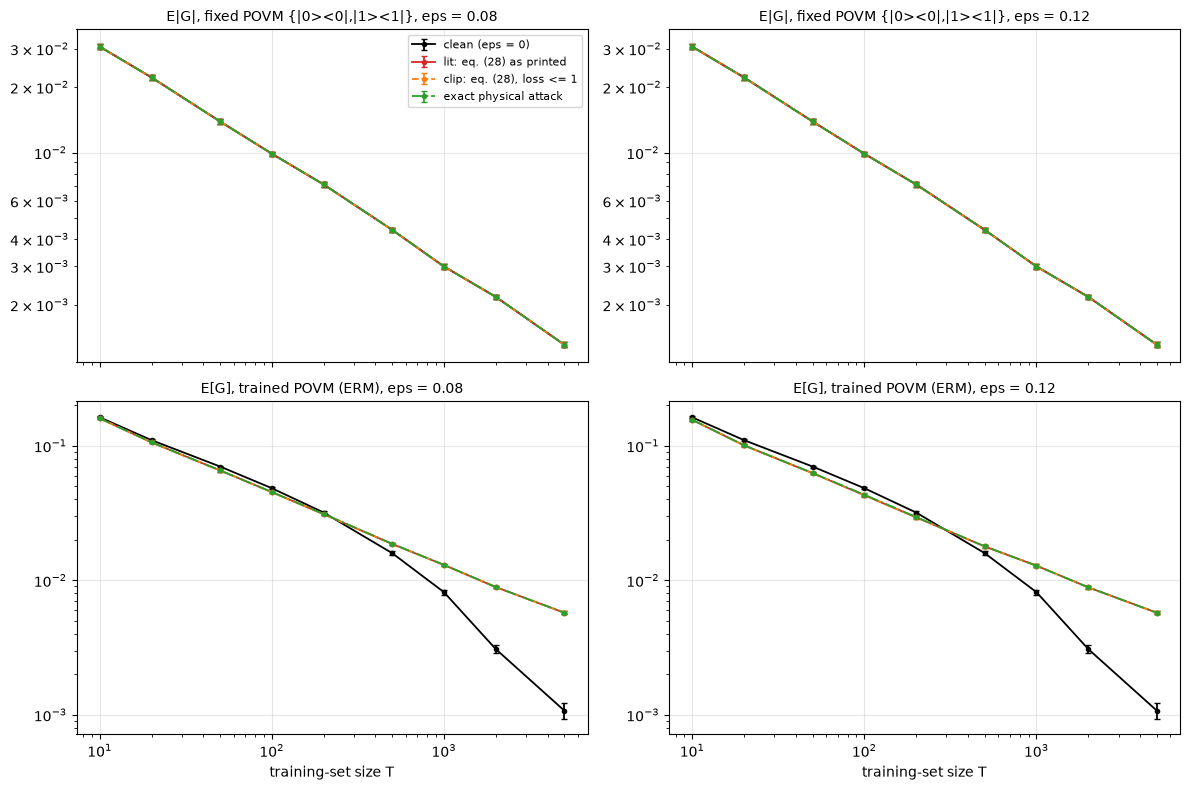

,variant,eps,T,absG_fix,G_erm,G_erm_se,d_G_erm,d_G_erm_se,U,R,d_R,d_R_se,excess
0,clean,0.00,10,0.03065,0.16279,0.00255,0.00000,0.00000,0.16402,0.15395,0.00000,0.00000,0.02152
1,lit,0.08,10,0.03065,0.15996,0.00259,-0.00283,0.00032,0.16402,0.15364,-0.00031,0.00030,0.01360
2,lit,0.12,10,0.03065,0.15573,0.00271,-0.00706,0.00054,0.16402,0.15381,-0.00014,0.00045,0.01609
3,clean,0.00,20,0.02213,0.11010,0.00180,0.00000,0.00000,0.11196,0.11694,0.00000,0.00000,0.01963
4,lit,0.08,20,0.02213,0.10600,0.00188,-0.00410,0.00038,0.11196,0.11735,0.00041,0.00020,0.00945
5,lit,0.12,20,0.02213,0.10061,0.00199,-0.00949,0.00059,0.11196,0.11781,0.00086,0.00030,0.00863
6,clean,0.00,50,0.01389,0.07012,0.00119,0.00000,0.00000,0.07273,0.07145,0.00000,0.00000,0.01821
7,lit,0.08,50,0.01389,0.06556,0.00127,-0.00456,0.00040,0.07273,0.07177,0.00032,0.00013,0.00434
8,lit,0.12,50,0.01389,0.06259,0.00132,-0.00753,0.00051,0.07273,0.07206,0.00061,0.00019,0.00392
9,clean,0.00,100,0.00987,0.04836,0.00089,0.00000,0.00000,0.05199,0.05231,0.00000,0.00000,0.01578


In [13]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
Ts = np.array(T_LIST)
styles = {"clean": ("k", "-", "clean (eps = 0)"), "lit": ("#d62728", "-", "lit: eq. (28) as printed"),
          "clip": ("#ff7f0e", "--", "clip: eq. (28), loss <= 1"), "exact": ("#2ca02c", "-.", "exact physical attack")}
for col, eps in enumerate(EPS_LIST):
    for row, (metric, name) in enumerate([("absG_fix", "E|G|, fixed POVM {|0><0|,|1><1|}"), ("G_erm", "E[G], trained POVM (ERM)")]):
        ax = axes[row, col]
        for v, (colr, ls, lab) in styles.items():
            d = RES[(RES.variant == v) & (RES.eps == (0.0 if v == "clean" else eps))].set_index("T")
            ax.errorbar(Ts, d[metric], yerr=d[metric + "_se"], color=colr, ls=ls, marker="o", ms=3, lw=1.3, capsize=2, label=lab)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(f"{name}, eps = {eps}", fontsize=10)
        if row == 1: ax.set_xlabel("training-set size T")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

# table at a few T
tab = RES[RES.variant.isin(["clean", "lit"])][["variant", "eps", "T", "absG_fix", "G_erm", "G_erm_se", "d_G_erm", "d_G_erm_se", "U", "R", "d_R", "d_R_se", "excess"]]
display(tab.round(5).reset_index(drop=True))

**Sensitivity to the gate convention.** For the paper's gate angles taken literally the embedded states are never strongly polarised against the true class along `z`, so for the paper's fixed POVM the three attack readings coincide (they differ only where `eq. (28)` would leave the Bloch ball). With the half-angle convention of common libraries the states are more polarised and the readings can differ. The next cell repeats the fixed-POVM study for both conventions at `T = T_BASELINE` (many more training sets, since this is cheap): population risk `L_eps`, `E|G|`, and its paired difference to the clean run (positive means the adversarial error is larger).

In [14]:
def fixed_povm_table(S, variant, eps):
    """Loss of the paper's POVM {|0><0|,|1><1|} on every (input, class) cell for an attack variant; S = Bloch vectors."""
    ez = np.array([[0.0, 0.0, 1.0]])
    p0 = (1 + S[:, 2]) / 2
    P = np.stack([p0, 1 - p0])
    if eps > 0:
        if variant == "lit":
            P = P - eps / 2
        elif variant == "clip":
            P = np.maximum(P - eps / 2, 0)
        else:
            m0 = min_dot_in_bloch(S, ez, eps)[0]; m1 = min_dot_in_bloch(S, -ez, eps)[0]
            P = np.stack([(1 + m0) / 2, (1 + m1) / 2])
    return np.concatenate([1 - P[0], 1 - P[1]])

rng_sens = np.random.default_rng(SEED + 7)
N_SENS = max(N_MC, 400)
SENS_ROWS = []
for a, name in ((1.0, "literal"), (0.5, "half-angle")):
    S_a = bloch_conv(XS, a)
    tabs = {("clean", 0.0): fixed_povm_table(S_a, "lit", 0.0)}
    for v in VARIANTS:
        for e in EPS_LIST: tabs[(v, e)] = fixed_povm_table(S_a, v, e)
    pops = {k: t @ JOINT for k, t in tabs.items()}
    absg = {k: [] for k in tabs}; dabs = {k: [] for k in tabs}
    done = 0
    while done < N_SENS:
        B = min(CHUNK, N_SENS - done); done += B
        counts = rng_sens.multinomial(T_BASELINE, JOINT / JOINT.sum(), size=B)
        base = np.abs(pops[("clean", 0.0)] - counts @ tabs[("clean", 0.0)] / T_BASELINE)
        for k, t in tabs.items():
            g = np.abs(pops[k] - counts @ t / T_BASELINE)
            absg[k].append(g); dabs[k].append(g - base)
    for k in tabs:
        g, d = np.concatenate(absg[k]), np.concatenate(dabs[k])
        diff_mass = float(np.abs(tabs[k] - tabs[("lit", k[1])]) @ JOINT) if k[0] != "clean" else 0.0
        SENS_ROWS.append({"gates": name, "variant": k[0], "eps": k[1], "L_eps (population)": pops[k],
                          "E|G|": g.mean(), "paired diff to clean": d.mean(), "s.e.": d.std(ddof=1) / np.sqrt(len(d)),
                          "mass where loss differs from lit": diff_mass})
SENS = pd.DataFrame(SENS_ROWS)
display(SENS.round(5))
print(f"{N_SENS} training sets of size T = {T_BASELINE} per row. Under 'lit' the paired difference is exactly 0 (identity above); under 'clip'/'exact' it is the effect of the x-dependent part of the attack.")

,gates,variant,eps,L_eps (population),E|G|,paired diff to clean,s.e.,mass where loss differs from lit
0,literal,clean,0.00,0.49997,0.00302,0.00000,0.0,0.00000
1,literal,lit,0.08,0.53997,0.00302,-0.00000,0.0,0.00000
2,literal,lit,0.12,0.55997,0.00302,-0.00000,0.0,0.00000
3,literal,clip,0.08,0.53997,0.00302,-0.00000,0.0,0.00000
4,literal,clip,0.12,0.55997,0.00302,-0.00000,0.0,0.00000
5,literal,exact,0.08,0.53997,0.00302,-0.00000,0.0,0.00000
6,literal,exact,0.12,0.55997,0.00302,-0.00000,0.0,0.00000
7,half-angle,clean,0.00,0.53300,0.00631,0.00000,0.0,0.00000
8,half-angle,lit,0.08,0.57300,0.00631,0.00000,0.0,0.00000
9,half-angle,lit,0.12,0.59300,0.00631,0.00000,0.0,0.00000


1000 training sets of size T = 1000 per row. Under 'lit' the paired difference is exactly 0 (identity above); under 'clip'/'exact' it is the effect of the x-dependent part of the attack.


## 7. Classical baseline on the same quantised scalar inputs

The input of the whole experiment is one real number `x`, so the natural classical competitors are the **Bayes-optimal rule** (posterior `P(c=0|x) = sigmoid(2x)` for the two unit-variance Gaussians; as a hard classifier, the threshold `x >= 0`) and **logistic regression** trained on the same `T = T_BASELINE` quantised samples. Each model produces a probability vector over the two classes, which is the classical, commutative special case of a POVM measurement, and is scored with the paper's loss (probability of error) and with the usual 0/1 error.

Two attacks at the same budget `eps` are applied to every model:

* **State-space `l1` attack** (the classical analogue of the paper's `p = 1` attack): the output distribution `(p_0, p_1)` is moved by at most `eps` in `l1`, i.e. `eps/2` of probability mass is taken from the true class. For a classical probability vector this is exact: the loss becomes `1 - max(0, p_c - eps/2)`. For the quantum POVM rows the `exact` (physical) and `lit` (eq. 28) values are shown.
* **Input-space attack**: the adversary shifts the scalar input by at most `eps`, `|dx| <= eps`, to maximise the loss (evaluated exactly on the grid). This is the attack a practitioner of classical adversarial learning would use; it is not part of the paper but makes the budget comparable.

The quantum rows are: the paper's fixed POVM `{|0><0|, |1><1|}`; the POVM trained by empirical-risk minimisation on `T_BASELINE` samples (standard training); and the same trained adversarially with the `exact` attack at the budget of the column. Seeds vary the training sets; the table shows mean (std over `N_SEEDS_BASE` seeds).

In [15]:
def p0_quantum(j, x):
    """class-0 probability Tr(Pi_0 rho(x)) of candidate POVM j at arbitrary inputs x."""
    if j < N_DIR: return (1 + bloch_vectors(x) @ DIRS[j]) / 2
    return np.zeros(len(x)) if j == N_DIR else np.ones(len(x))

def evaluate(p0_fn, eps_list=EPS_LIST):
    """Population metrics of a classifier given by its class-0 probability p0(x), exactly on the grid."""
    p0 = p0_fn(XS); P = np.stack([p0, 1 - p0])                         # (2,G)
    pred_wrong = np.stack([(p0 < 0.5), (p0 >= 0.5)])                   # hard decision: class 0 iff p0 >= 0.5
    out = {"err01": float((JOINT * pred_wrong.reshape(-1)).sum()), "soft": float((JOINT * (1 - P).reshape(-1)).sum())}
    for e in eps_list:
        out[f"state_l1_{e}"] = float((JOINT * (1 - np.maximum(P - e / 2, 0)).reshape(-1)).sum())      # exact for a probability vector
        nsh = int(round(e / GRID_H)); shifts = np.arange(-nsh, nsh + 1) * GRID_H
        px = p0_fn((XS[:, None] + shifts[None, :]).ravel()).reshape(G, -1)
        soft_adv = np.stack([(1 - px).max(1), (px).max(1)])             # max over shifts of the loss: class 0 -> 1-p0, class 1 -> 1-p1 = p0
        wrong_adv = np.stack([(px < 0.5).any(1), (px >= 0.5).any(1)])
        out[f"input_soft_{e}"] = float((JOINT * soft_adv.reshape(-1)).sum())
        out[f"input_01_{e}"] = float((JOINT * wrong_adv.reshape(-1)).sum())
    return out

rows = []
# Bayes-optimal rules (no training)
rows.append(("Bayes posterior sigmoid(2x), soft", evaluate(lambda x: 1 / (1 + np.exp(-2 * x))), None))
rows.append(("Bayes threshold x >= 0, hard", evaluate(lambda x: (x >= 0).astype(float)), None))

# logistic regression, quantum ERM (standard and adversarial) over seeds
lr_res, q_std, q_adv = [], [], {e: [] for e in EPS_LIST}
q_fixed = evaluate(lambda x: p0_quantum(0, x))
for sd in range(N_SEEDS_BASE):
    r = np.random.default_rng(SEED + 100 + sd)
    cell = r.choice(2 * G, size=T_BASELINE, p=JOINT / JOINT.sum()); k_tr, c_tr = cell % G, cell // G
    clf = LogisticRegression(C=1.0).fit(XS[k_tr].reshape(-1, 1), c_tr)
    wlr, blr = clf.coef_[0, 0], clf.intercept_[0]
    lr_res.append(evaluate(lambda x: 1 - 1 / (1 + np.exp(-(wlr * x + blr)))))
    counts = np.bincount(cell, minlength=2 * G)[None, :]
    j_std = int((counts @ LT[("clean", 0.0)].T / T_BASELINE).argmin())
    q_std.append(evaluate(lambda x: p0_quantum(j_std, x)))
    for e in EPS_LIST:
        j_adv = int((counts @ LT[("exact", e)].T / T_BASELINE).argmin())
        q_adv[e].append(evaluate(lambda x: p0_quantum(j_adv, x), eps_list=(e,)))

def mean_std(lst, key):
    v = np.array([d[key] for d in lst if key in d]); return f"{v.mean():.4f} ({v.std():.4f})"
COLS = ["err01", "soft"] + [f"state_l1_{e}" for e in EPS_LIST] + [f"input_soft_{e}" for e in EPS_LIST] + [f"input_01_{e}" for e in EPS_LIST]
def fmt_row(name, res_list):
    return [name] + [mean_std(res_list, c) for c in COLS]
table = []
for name, d, _ in rows: table.append(fmt_row(name, [d]))
table.append(fmt_row(f"Logistic regression (T={T_BASELINE}), soft", lr_res))
table.append(fmt_row("Quantum, paper's fixed POVM {|0><0|,|1><1|}", [q_fixed]))
table.append(fmt_row(f"Quantum POVM, ERM standard (T={T_BASELINE})", q_std))
adv_row = ["Quantum POVM, adversarially trained at the column eps (exact attack)", "", ""]
for e in EPS_LIST: adv_row.append(mean_std(q_adv[e], f"state_l1_{e}"))
for e in EPS_LIST: adv_row.append(mean_std(q_adv[e], f"input_soft_{e}"))
for e in EPS_LIST: adv_row.append(mean_std(q_adv[e], f"input_01_{e}"))
table.append(adv_row)
BASE = pd.DataFrame(table, columns=["model", "clean 0/1 err", "clean soft loss (paper loss)"]
                    + [f"state-l1 adv loss eps={e}" for e in EPS_LIST] + [f"input-space adv soft loss eps={e}" for e in EPS_LIST]
                    + [f"input-space adv 0/1 err eps={e}" for e in EPS_LIST])
pd.set_option("display.max_colwidth", 70)
display(BASE.T)

# the quantum fixed POVM under the three readings of the state-space attack, for completeness
for v in ("lit", "clip", "exact"):
    print(f"fixed POVM, paper loss L_1,eps under '{v}': " + ", ".join(f"eps={e}: {POP[(v, e)][0]:.4f}" for e in EPS_LIST) + f"   (clean {POP[('clean', 0.0)][0]:.4f})")
print(f"Bayes error Phi(-1) = {ndtr(-1):.4f}")

,0,1,2,3,4,5
model,"Bayes posterior sigmoid(2x), soft","Bayes threshold x >= 0, hard","Logistic regression (T=1000), soft","Quantum, paper's fixed POVM {|0><0|,|1><1|}","Quantum POVM, ERM standard (T=1000)","Quantum POVM, adversarially trained at the column eps (exact attack)"
clean 0/1 err,0.1587 (0.0000),0.1587 (0.0000),0.1589 (0.0004),0.5010 (0.0000),0.4745 (0.0115),
clean soft loss (paper loss),0.2248 (0.0000),0.1587 (0.0000),0.2272 (0.0047),0.5000 (0.0000),0.4819 (0.0080),
state-l1 adv loss eps=0.08,0.2647 (0.0000),0.1923 (0.0000),0.2671 (0.0047),0.5400 (0.0000),0.5187 (0.0025),0.5198 (0.0007)
state-l1 adv loss eps=0.12,0.2846 (0.0000),0.2091 (0.0000),0.2870 (0.0047),0.5600 (0.0000),0.5363 (0.0037),0.5300 (0.0000)
input-space adv soft loss eps=0.08,0.2432 (0.0000),0.1788 (0.0000),0.2455 (0.0045),0.5347 (0.0000),0.5188 (0.0080),0.5012 (0.0051)
input-space adv soft loss eps=0.12,0.2527 (0.0000),0.1894 (0.0000),0.2549 (0.0044),0.5516 (0.0000),0.5372 (0.0158),0.5000 (0.0000)
input-space adv 0/1 err eps=0.08,0.1788 (0.0000),0.1788 (0.0000),0.1791 (0.0004),0.6028 (0.0000),0.5182 (0.0089),0.5010 (0.0044)
input-space adv 0/1 err eps=0.12,0.1894 (0.0000),0.1894 (0.0000),0.1897 (0.0004),0.6537 (0.0000),0.5403 (0.0176),0.5000 (0.0000)


fixed POVM, paper loss L_1,eps under 'lit': eps=0.08: 0.5400, eps=0.12: 0.5600   (clean 0.5000)
fixed POVM, paper loss L_1,eps under 'clip': eps=0.08: 0.5400, eps=0.12: 0.5600   (clean 0.5000)
fixed POVM, paper loss L_1,eps under 'exact': eps=0.08: 0.5400, eps=0.12: 0.5600   (clean 0.5000)
Bayes error Phi(-1) = 0.1587


## 8. Paper versus this notebook

The paper gives no numbers for Fig. 2, so each claim is a qualitative statement and is judged by a rule written down before looking at the data (the same rule for every panel):

1. *Adversarial error larger than non-adversarial.* "reproduced" if, for at least 80 % of the `T` values, the adversarially trained classifier's `G_1,eps` exceeds the standard `G` by more than two standard errors of the paired difference (same training sets); "not reproduced" otherwise (we report the number of `T` values with larger / smaller / indistinguishable).
2. *Both errors tend to 0.* "reproduced" if `G(T_max) < G(T_min)/3` and the log-log slope over `T >= T_BASELINE/10` is at most -0.3 (a `1/sqrt(T)` law has slope -0.5; a steeper decay also counts as tending to 0).
3. *Bound (18) tracks the trend for `eps <= 2 Delta`.* "reproduced" if (18) is above the measured error and above the numerical uniform deviation (17) at every `T` and its log-log slope differs from the measured slope by at most 0.2. The panel `eps = 0.08` is inside Assumption 1 only under the paper's `Delta`; under the computed `Delta` the same numbers are reported as a check outside the theorem's range.
4. *Adversarial Rademacher complexity exceeds the non-adversarial one.* "reproduced" if `R_1,eps > R` for at least 80 % of the `T` values and the paired difference exceeds two standard errors for at least half of them; "weakly reproduced" if only the first part holds; otherwise "not reproduced".
5. *Bound (20) for `eps > 2 Delta` captures the decrease but is loose.* "reproduced" if (20) is above the measured error everywhere and its ratio to the measured error at the largest `T` exceeds 5.

In [16]:
def slope(y, tmin=None):
    Ts_ = np.array(T_LIST, dtype=float); m = Ts_ >= (tmin if tmin else Ts_[0])
    return float(np.polyfit(np.log(Ts_[m]), np.log(np.asarray(y)[m]), 1)[0])
Ts = np.array(T_LIST, dtype=float)
TMIN_SLOPE = max(T_BASELINE / 10, T_LIST[0])
rows = []

# Claim 1: adversarial > non-adversarial (trained classifier, all three readings, and the fixed POVM)
for variant in ("lit", "clip", "exact"):
    for e in EPS_LIST:
        g0, g1 = curve("clean", 0.0, "G_erm"), curve(variant, e, "G_erm")
        d, se = curve(variant, e, "d_G_erm"), curve(variant, e, "d_G_erm_se")         # paired with the clean run
        n_gt, n_lt = int((d > 2 * se).sum()), int((d < -2 * se).sum()); n_eq = len(d) - n_gt - n_lt
        pos = [int(T_) for T_, a_, b_ in zip(T_LIST, d, se) if a_ > 2 * b_]; neg = [int(T_) for T_, a_, b_ in zip(T_LIST, d, se) if a_ < -2 * b_]
        if n_gt >= 0.8 * len(d): verdict = "reproduced"
        elif n_gt and n_lt: verdict = f"partly: larger only for T >= {min(pos)}, smaller for T <= {max(neg)}" if min(pos) > max(neg) else "mixed (sign changes with T)"
        else: verdict = "not reproduced"
        rows.append({"claim": "1. G_1,eps (adv. trained) > G (standard)", "setting": f"{variant}, eps={e}",
                     "paper": "adversarial error larger", "notebook": f"larger at {n_gt}, smaller at {n_lt}, indistinguishable at {n_eq} of {len(d)} T values; ratio at T_max {g1.iloc[-1] / g0.iloc[-1]:.2f}",
                     "verdict": verdict})
for variant in ("lit", "clip", "exact"):
    for e in EPS_LIST:
        d, se = curve(variant, e, "d_absG_fix"), curve(variant, e, "d_absG_fix_se")
        n_gt, n_lt = int((d > 2 * se).sum()), int((d < -2 * se).sum()); n_eq = len(d) - n_gt - n_lt
        rows.append({"claim": "1. E|G_1,eps| > E|G|, fixed POVM", "setting": f"{variant}, eps={e}", "paper": "adversarial error larger",
                     "notebook": f"larger at {n_gt}, smaller at {n_lt}, indistinguishable at {n_eq} of {len(d)}",
                     "verdict": "reproduced" if n_gt >= 0.8 * len(d) else "not reproduced"})
for _, r_ in SENS[SENS.variant.isin(["clip", "exact"])].iterrows():
    d_, se_ = r_["paired diff to clean"], r_["s.e."]
    rows.append({"claim": "1b. E|G_1,eps| > E|G|, fixed POVM (gate-convention sensitivity)", "setting": f"{r_['gates']} gates, {r_['variant']}, eps={r_['eps']}",
                 "paper": "adversarial error larger", "notebook": f"paired difference {d_:+.2e} +/- {se_:.1e} at T={T_BASELINE}; loss differs from lit on probability mass {r_['mass where loss differs from lit']:.1e}",
                 "verdict": ("not reproduced (identical: this attack reading changes no loss here)" if r_["mass where loss differs from lit"] < 1e-6 else
                             "reproduced" if d_ > 2 * se_ else ("not reproduced (smaller)" if d_ < -2 * se_ else "not reproduced (indistinguishable)"))})
# Claim 2: both tend to 0
for key, lab in [(("clean", 0.0), "G standard")] + [(("lit", e), f"G_1,eps lit eps={e}") for e in EPS_LIST]:
    for metric, mname in (("G_erm", "trained POVM"), ("absG_fix", "fixed POVM")):
        y = RES[(RES.variant == key[0]) & (RES.eps == key[1])].set_index("T")[metric]
        ok = (y.iloc[-1] < y.iloc[0] / 3) and (slope(y, TMIN_SLOPE) <= -0.3)
        rows.append({"claim": "2. error tends to 0 with T", "setting": f"{lab}, {mname}", "paper": "tends to 0",
                     "notebook": f"{y.iloc[0]:.4f} at T={T_LIST[0]} -> {y.iloc[-1]:.5f} at T={T_LIST[-1]}; log-log slope {slope(y, TMIN_SLOPE):+.2f}",
                     "verdict": "reproduced" if ok else "not reproduced"})
# Claim 3: bound (18) for eps = 0.08 (left panel)
for e in EPS_LIST:
    for reading, inside in (("paper Delta=0.05", e <= 2 * DELTA_PAPER), ("computed Delta=0.025", e <= 2 * DELTA_COMPUTED + 1e-12)):
        g1 = curve("lit", e, "G_erm"); u17 = 2 * curve("lit", e, "R") + conf_term(Ts)
        b = bound_18(Ts, e)
        valid = bool((b >= g1.values).all() and (b >= u17.values).all())
        sl_b, sl_g = slope(b, TMIN_SLOPE), slope(g1, TMIN_SLOPE)
        ok = valid and abs(sl_b - sl_g) <= 0.2
        rows.append({"claim": "3. bound (18) tracks the trend", "setting": f"eps={e}, {reading}: Assumption 1 {'holds' if inside else 'violated'}",
                     "paper": "tracks for eps <= 2 Delta" if e <= 0.1 else "(not claimed: eps > 2 Delta)",
                     "notebook": f"above G and (17) everywhere: {valid}; slope bound {sl_b:+.2f} vs measured {sl_g:+.2f}; ratio bound/G at T_max {b[-1] / g1.iloc[-1]:.0f}x",
                     "verdict": ("reproduced" if ok else "not reproduced") + ("" if inside else " (outside theorem range)")})
# Claim 4: Rademacher complexities
for e in EPS_LIST:
    r0, r1 = curve("clean", 0.0, "R"), curve("lit", e, "R")
    dR, dRse = curve("lit", e, "d_R"), curve("lit", e, "d_R_se")
    n_gt = int((dR > 0).sum()); n_sig = int((dR > 2 * dRse).sum())
    rows.append({"claim": "4. adversarial Rademacher complexity > non-adversarial", "setting": f"lit, eps={e}", "paper": "exceeds",
                 "notebook": f"larger at {n_gt} of {len(r0)} T values ({n_sig} beyond 2 paired s.e.); ratio at T_max {r1.iloc[-1] / r0.iloc[-1]:.3f}",
                 "verdict": ("reproduced" if n_sig >= 0.5 * len(r0) else "weakly reproduced (effect below 1 %, within noise at most T)") if n_gt >= 0.8 * len(r0) else "not reproduced"})
# Claim 5: bound (20) for eps = 0.12
for e in EPS_LIST:
    g1 = curve("lit", e, "G_erm"); b = bound_20(Ts, e)
    ok = bool((b >= g1.values).all()) and (b[-1] / g1.iloc[-1] > 5)
    rows.append({"claim": "5. bound (20) valid but loose for eps > 2 Delta", "setting": f"eps={e}", "paper": "captures decrease, loose",
                 "notebook": f"above G everywhere: {bool((b >= g1.values).all())}; (20) falls only from {b[0]:.3f} to {b[-1]:.3f}; ratio to G at T_max {b[-1] / g1.iloc[-1]:.0f}x",
                 "verdict": "reproduced" if ok else "not reproduced"})
# Claim 6: Delta
rows.append({"claim": "6. Delta = 0.05 for q = 0.05", "setting": "min eigenvalue of rho(x)", "paper": "Delta = 0.05",
             "notebook": f"alpha_min = {ALPHA_MIN:.4f} = q/2", "verdict": "not reproduced (paper constant inconsistent; computed Delta = 0.025)"})
VERD = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 250)
display(VERD[["claim", "setting", "paper", "notebook", "verdict"]])
print("\nFree-text paper numbers: none are given for Fig. 2 (values read off a figure only); all verdicts above are on qualitative claims.")
print(f"Total wall-clock time of the notebook: {(time.time() - T0) / 60:.1f} minutes (FAST_MODE = {FAST_MODE})")

,claim,setting,paper,notebook,verdict
0,"1. G_1,eps (adv. trained) > G (standard)","lit, eps=0.08",adversarial error larger,"larger at 4, smaller at 5, indistinguishable at 0 of 9 T values; ratio at T_max 5.34","partly: larger only for T >= 500, smaller for T <= 200"
1,"1. G_1,eps (adv. trained) > G (standard)","lit, eps=0.12",adversarial error larger,"larger at 4, smaller at 5, indistinguishable at 0 of 9 T values; ratio at T_max 5.34","partly: larger only for T >= 500, smaller for T <= 200"
2,"1. G_1,eps (adv. trained) > G (standard)","clip, eps=0.08",adversarial error larger,"larger at 4, smaller at 5, indistinguishable at 0 of 9 T values; ratio at T_max 5.34","partly: larger only for T >= 500, smaller for T <= 200"
3,"1. G_1,eps (adv. trained) > G (standard)","clip, eps=0.12",adversarial error larger,"larger at 4, smaller at 5, indistinguishable at 0 of 9 T values; ratio at T_max 5.34","partly: larger only for T >= 500, smaller for T <= 200"
4,"1. G_1,eps (adv. trained) > G (standard)","exact, eps=0.08",adversarial error larger,"larger at 4, smaller at 5, indistinguishable at 0 of 9 T values; ratio at T_max 5.34","partly: larger only for T >= 500, smaller for T <= 200"
5,"1. G_1,eps (adv. trained) > G (standard)","exact, eps=0.12",adversarial error larger,"larger at 4, smaller at 5, indistinguishable at 0 of 9 T values; ratio at T_max 5.34","partly: larger only for T >= 500, smaller for T <= 200"
6,"1. E|G_1,eps| > E|G|, fixed POVM","lit, eps=0.08",adversarial error larger,"larger at 0, smaller at 0, indistinguishable at 9 of 9",not reproduced
7,"1. E|G_1,eps| > E|G|, fixed POVM","lit, eps=0.12",adversarial error larger,"larger at 0, smaller at 0, indistinguishable at 9 of 9",not reproduced
8,"1. E|G_1,eps| > E|G|, fixed POVM","clip, eps=0.08",adversarial error larger,"larger at 0, smaller at 0, indistinguishable at 9 of 9",not reproduced
9,"1. E|G_1,eps| > E|G|, fixed POVM","clip, eps=0.12",adversarial error larger,"larger at 0, smaller at 0, indistinguishable at 9 of 9",not reproduced



Free-text paper numbers: none are given for Fig. 2 (values read off a figure only); all verdicts above are on qualitative claims.
Total wall-clock time of the notebook: 2.0 minutes (FAST_MODE = False)


## 9. Reading the paper critically

All numbers below are from the full run (`FAST_MODE = False`, 1000 training sets per `T`, 402 candidate POVMs, seed 42).

* **The figure cannot be checked numerically.** Section VI gives no values and no definition of how the random generalisation error becomes one curve. Everything here is therefore a *qualitative* verdict, and the verdicts depend on that missing definition (see the next point).
* **For a fixed POVM the adversarial and the non-adversarial generalisation errors are identical under eq. (28).** The attack of Appendix A raises the loss of a projective measurement by the same `eps/2` for every input, so `L_{1,eps}(Pi) - L_hat_{1,eps}(Pi) = L(Pi) - L_hat(Pi)` exactly (checked to 1e-16). The claim "the adversarial generalisation error is larger than the non-adversarial one" cannot come from the fixed POVM `{|0><0|,|1><1|}` that the caption names, with eq. (28), whatever the training-set size. Replacing (28) by the true physical maximum or by a loss capped at 1 changes nothing for the literal gates (the three readings differ on a probability mass below 1e-16) and very little for half-angle gates (mass 1e-3, effect `-4e-5`).
* **For the trained (adversarially trained) POVM the claim holds only for large `T`.** `G_1,eps` is *smaller* than `G` for `T <= 200` (paired difference `-0.003` at `T = 10` for `eps = 0.08`, `-0.007` for `eps = 0.12`) and *larger* for `T >= 500`, up to a factor 5.3 at `T = 5000` (0.0057 versus 0.0011). The reason is not generalisation theory but the attack itself. Every non-trivial projective measurement loses exactly `eps/2` under (28), the two trivial POVMs lose nothing, and for this embedding the best possible gain over a coin flip is only `0.5 - 0.4765 = 0.0235` (Helstrom, section 3), below `eps/2 = 0.04`. Adversarial training therefore converges to the *constant* classifier (its excess risk under the attack is below 2e-4 from `T = 1000` on and 0 at `T = 5000`), whose generalisation error decays like `1/sqrt(T)` (slope -0.5), while the standard classifier converges to the optimal measurement and its error decays faster (slope -0.98).
* **Both errors tend to 0.** Yes: standard 0.163 at `T = 10` to 0.0011 at `T = 5000`; adversarial 0.160 (`eps = 0.08`) and 0.156 (`eps = 0.12`) to 0.0057. The paper's bounds predict `1/sqrt(T)`; the measured adversarial slope is -0.53 and -0.51.
* **Bound (18) is valid and has the right slope, but it is not informative about the adversary.** It lies 13 times above the adversarial error at `T = 5000`, and it is almost on top of the non-adversarial bound (10): the `eps` term `2 sqrt(K/T) eps` is only about 4 % (`eps = 0.08`) and 6 % (`eps = 0.12`) of it. The measured increase of the Rademacher complexity caused by the attack is below 1 % (`R_1,eps / R = 1.004` and `1.007` at `T = 5000`; the paired difference at `T = 1000` is `4e-5` and `9e-5`), about two orders of magnitude smaller than what the `eps` term of (18) allows. The numerical bounds (13) and (17) are visually identical (dotted curves coincide in the figure).
* **Bound (20) behaves as the paper says.** It stays above the measured error but flattens at `eps sqrt(2d) = 2 eps` (0.16 and 0.24), 40 to 54 times the adversarial error at `T = 5000`, because the perturbation term in its proof has no `1/sqrt(T)` factor.
* **The paper's constant `Delta = 0.05` is wrong for the stated embedding.** `rho(x)` has minimum eigenvalue `q/2 = 0.025` (section 3). Under the computed value both panels are outside Assumption 1 (`2 Delta = 0.05`), under the paper's value only the right panel is. The numbers do not care: bound (18) is above the data in both panels. For the paper's POVM the printed attack does not even leave the Bloch ball in either panel; other measurement directions do (95 % and 99.8 % of the 400 candidate projective POVMs for `eps = 0.08` and `0.12`; for the worst one the attack leaves the state space on 35 % and 42 % of the probability mass), which is why the assumption is needed for a statement about *all* POVMs.
* **The classifier of Fig. 2 is not a good classifier.** With the gate angles taken literally the paper's POVM has error 0.5010, the best POVM on the embedded states 0.4765, and a classical logistic regression on the same scalar input 0.1589 (Bayes error 0.1587). Under the same budget the classical model loses `eps/2` in the state-space attack (soft loss 0.2272 to 0.2671 at `eps = 0.08`) or 2 points of 0/1 error in the input-space attack (0.1589 to 0.1791), while the quantum model is within 0.03 of a coin flip before the attack (0.4745 for the trained POVM) and at or above 0.5 after it. With half-angle library gates the picture improves only a little (best error 0.4153). The experiment illustrates the *bounds*; it says nothing about the practical robustness of quantum classifiers.
* **Confidence.** `delta = 0.8` makes the high-probability statements hold with probability 0.2 only; a usual `delta` such as 0.05 raises every bound by `sqrt(2 ln(40)/T)` versus `sqrt(2 ln(2.5)/T)`, a factor 2.0 in that term.
* **Not tested.** `p = infinity` attacks and bound (19), the mismatch setting of Theorem 5 and Lemma 2, and quantum hardware were not part of Section VI and are not simulated here.

## 10. Exercises

1. **Grid independence.** Change `GRID_H` to 0.05 and 0.002 (and `GRID_MAX` to 8). Which quantities in the notebook change (`I_2`, the bounds, the curves)? Why must `I_2` converge as the grid is refined?
2. **Make the paper's constants consistent.** Set `Q_NOISE = 0.1` so that the minimum eigenvalue really is `Delta = 0.05`, keep `EPS_LIST = (0.08, 0.12)`, and rerun. Does the eq. (28) attack stay a physical state for every POVM at `eps = 0.08`? Which verdicts change?
3. **Half-angle gates.** Replace `S_GRID` by `bloch_conv(XS, 0.5)` (and rebuild `RHO_GRID`, the circuit with `qml.RX(x)` and `exp(-i theta.sigma/2)`, and the loss tables). Is the adversarially trained classifier still the constant classifier? Is `G_1,eps > G` for more training-set sizes than in the literal case?
4. **The `p = infinity` attack.** Implement the inner maximisation of Appendix A.B for one qubit (eigenvalue shift `eps` with the sign of `Pi_c - alpha_med I`), the bound (19), and compare it with the measured error. How much larger is the `eps` term, as the paper claims, by the factor `d = 2`?
5. **A sharper confidence level.** Recompute (10), (18) and (20) with `delta = 0.05` instead of 0.8 and find the training-set size at which each bound drops below 0.1. Compare with the size at which the measured error does.